# 09D — Football interpretation and case studies

**Goal.** Turn measured differences into qualified scouting language, on real athletes.

**Interpretation registry.** Every metric shown anywhere in the product answers seven questions: what is measured · what it means physically · how it differs from official testing · how reliable it is · which football movements may be physically related · what a scout should look at next · what cannot be concluded.

**Case studies — ten declared types, selected by pre-draft rules.**

1. same forty, different acceleration curve · 2. same top speed, different speed development · 3. same first 10 yards, different later acceleration · 4. similar official tests, distant movement fingerprints · 5. high-confidence movement difference · 6. apparent difference inside the measurement uncertainty · 7. position-specific comparison · 8. repeat-attempt inconsistency · 9. tracking-quality limitation · 10. similar movement, observed NFL movement shown.

The rule is deterministic (largest contrast among qualifying twin pairs, no athlete twice in a type). **No NFL outcome value enters any selection.** Type 10 needs both athletes to have enough tracked NFL windows so that their observed NFL movement can be *shown afterwards*: that eligibility uses the exposure count only and is flagged. A type without a qualifying pair is reported as absent — nothing is forced to reach a target count.

**Three views per case.** Scout (what differs, is it measurable, which film, what stays uncertain) · position coach (movement phase, physical demand, targeted testing, measurement limits — no training prescription) · general manager (new information beyond official tests, strength of evidence, redundancy, uncertainty, whether additional evaluation is justified — no grade, no ranking).

**Wording rule, enforced in code.** *This player shows stronger observed acceleration over the measured speed band; the corresponding football advantage has not been established.* Never: *quicker acceleration means a better player.*

**Prerequisites (same `RUN_MODE`).** 01, 02, 07D, 09A, 09B, 09C. Optional: 05B athlete outcomes (exposure counts and the display of case type 10).

In [1]:
RUN_MODE = 'full'             # 'smoke' | 'full'
SEED = 20261011
FORCE_REBUILD = False         # interface parity: every table of this notebook is recomputed on each run
SAVE_TABLES = True
SAVE_FIGURES = True
NUM_WORKERS = 0
EXPERIMENT_VERSION = '09D.1'
CASES_PER_TYPE = 2            # cases kept per declared type (types 1–6, 8–10); type 7 keeps one per position
NFL_OUTCOME_SHOWN = 'O2.accel_sust05_mean'   # the frozen primary NFL movement target (D-05-1): DISPLAYED for case type 10, never a selection input
WRITE_CASE_REPORTS = True     # one self-contained HTML report per case under reports/milestone09/cases
SHOW_CASE = 0                 # index of the case whose three views are printed below

In [2]:
from nflbdb.data.config import Phase01Config, configure_runtime

cfg = Phase01Config.load()
configure_runtime(cfg)

from dataclasses import replace

import polars as pl
from IPython.display import Markdown, display

from nflbdb.data.utils import utc_now
from nflbdb.research.advanced_movement import checkpoint as ck
from nflbdb.research.advanced_movement import config as amc
from nflbdb.research.advanced_movement import intelligence_figures as ifg
from nflbdb.research.advanced_movement import intelligence_validation as iv
from nflbdb.research.advanced_movement import milestone09_artifacts as m9
from nflbdb.research.advanced_movement import movement_demands as md
from nflbdb.research.advanced_movement import movement_matching as mm
from nflbdb.research.advanced_movement import nfl_outcomes as no
from nflbdb.research.advanced_movement import scouting_interpretation as sin
from nflbdb.research.advanced_movement import sequences as seq
from nflbdb.research.advanced_movement import stopwatch_twins as stw
from nflbdb.research.advanced_movement.artifacts import IntelligenceStore
from nflbdb.research.advanced_movement.scoring import figures as sfig

controls = amc.NotebookControls(run_mode=RUN_MODE, force_rebuild=FORCE_REBUILD, save_figures=SAVE_FIGURES, save_tables=SAVE_TABLES,
                                seed=SEED, num_workers=NUM_WORKERS).validate()
store = IntelligenceStore(cfg, controls)
up = store.upstream
amc.seed_everything(controls.seed)
NB = {'01': '01_sequence_eda_and_alignment.ipynb', '02': '02_functional_pca_baseline.ipynb', '09A': '09a_nfl_movement_demand_atlas.ipynb',
      '09B': '09b_cross_domain_movement_matching.ipynb', '09C': '09c_stopwatch_twins_discovery.ipynb', '09D': '09d_football_interpretation_and_case_studies.ipynb'}

twins = store.require(stw.TWINS, NB['09C'])
diffs = store.require(stw.DIFFS, NB['09C'])
prospect = store.require(mm.PROSPECT, NB['09B'])
evidence = store.require(mm.EVIDENCE, NB['09B'])
freq = store.require(md.FREQUENCY, NB['09A'])
frames = up.require(seq.SEQ_FRAMES, NB['01'])
windows = up.require(ck.WINDOWS, NB['02'])
TC = replace(stw.TwinConfig(**store.read_json('stopwatch_twins_manifest', NB['09C'])['provenance']['twin_config']), cases_per_type=CASES_PER_TYPE)

# NFL side: exposure COUNTS for the eligibility of case type 10, and the outcome values that are only DISPLAYED afterwards
nfl = store.nfl.read(no.ATHLETE_OUTCOMES).filter(pl.col('outcome_id') == NFL_OUTCOME_SHOWN) if store.nfl.exists(no.ATHLETE_OUTCOMES) else None
EXPOSURE = dict(zip(nfl['nfl_id'].to_list(), nfl['n_windows'].to_list())) if nfl is not None else None
if EXPOSURE is None:
    print('NFL athlete outcomes absent for this run mode: case type 10 cannot be formed (reported as absent)')
PROV = {'notebook': NB['09D'], 'experiment_version': EXPERIMENT_VERSION, 'run_mode': controls.run_mode, 'seed': controls.seed, 'twin_config': TC.params(),
        'nfl_outcome_values_in_selection': 'none', 'nfl_quantity_in_selection': 'exposure count of case type 10 only', 'nfl_outcome_shown': NFL_OUTCOME_SHOWN}
save = lambda df, c: store.write(df, c, '09D', PROV) if controls.save_tables else df
label = 'SMOKE — wiring check, numbers are not results' if controls.smoke else 'FULL'
display(Markdown(f'**Run mode: `{controls.run_mode}`** ({label}) · {twins.height:,} twin pairs · {evidence.height} curve features · interpretation engine version {sin.VERSION}'))

**Run mode: `full`** (FULL) · 3,266 twin pairs · 8 curve features · interpretation engine version 1

## 1 · Synthetic checks

A generated reading always has its four sections, qualifies football relevance, disclaims causation and gives a practical follow-up; a pair without a distinguishable difference names no movement phase; three views per case; the wording guard refuses grades and ranking labels; every metric answers the seven questions.

In [3]:
validation = iv.run_all(iv.CHECKS_INTERPRETATION)
with pl.Config(fmt_str_lengths=220, tbl_rows=-1):
    display(validation)
iv.assert_all_passed(validation)

check,status,detail
str,str,str
"""interpretation_wording_and_views""","""PASS""","""generated readings are qualified, always give a follow-up, never grade or rank; three views per case; seven answers per metric"""


## 2 · Interpretation registry

The reliability column is filled from the executed evidence of 09B (and, for the two atlas features, the 08B.4 registry).

In [4]:
interpretation = save(pl.DataFrame(sin.interpretation_registry(evidence.to_dicts()), schema=m9.INTERPRETATION.columns), m9.INTERPRETATION)
with pl.Config(tbl_rows=-1, tbl_width_chars=320, fmt_str_lengths=120):
    display(interpretation)

13:11:33 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:09D] scouting_interpretation_registry: 12 rows → warehouse/gold/advanced_movement/intelligence_v1/scouting_interpretation_registry.parquet


metric,what_is_measured,physical_meaning,difference_from_official_testing,reliability,related_football_movements,what_to_look_at_next,what_cannot_be_concluded
str,str,str,str,str,str,str,str
"""cmb_forty""","""official time over 40 yards from a stationary start""","""average speed over the whole run in one number""","""it IS the official test""","""single official value: measurement error not estimable from this data""","""general straight-line speed (physical relation only)""","""use as today""","""how the time was built: two different speed curves can give the same time"""
"""cmb_ten_yd_split""","""official time over the first 10 yards""","""early acceleration as timed by the stopwatch""","""it IS an official split""","""single official value: measurement error not estimable from this data""","""short-area starts (physical relation only)""","""use as today""","""the shape of the acceleration inside those 10 yards"""
"""acc_2_4""","""mean acceleration while tracked speed rises from 2 to 4 yd/s""","""how hard speed is built in the first steps""","""inside the 10-yard split, which mixes this band with reaction and the next bands""","""unstable — repeat-attempt ICC 0.35 (372 athletes with a repeat); R² on official times 0.08 (09B local screen (raw ICC an…","""movements that start from rest or near rest: the first steps after the snap and short-area starts (physical relation onl…","""film of first steps; a timed start with split timing""","""whether it is used, or matters, in a game; the band spans very few 10 Hz frames"""
"""acc_4_6""","""mean acceleration while tracked speed rises from 4 to 6 yd/s""","""how hard speed is built in the middle of the acceleration""","""not isolated by any official split""","""unstable — repeat-attempt ICC 0.49 (375 athletes with a repeat); R² on official times 0.29 (09B local screen (raw ICC an…","""building speed while already moving: movements that develop over several yards after the first steps (physical relation …","""film of movements that develop over several yards; a rolling-start test""","""performance from a rolling start: the forty passes this band once, from rest"""
"""acc_6_8""","""mean acceleration while tracked speed rises from 6 to 8 yd/s""","""how hard speed is still built late in the acceleration""","""not isolated by any official split""","""moderately_repeatable_partly_beyond_stopwatch — repeat-attempt ICC 0.61 (375 athletes with a repeat); R² on official tim…","""reaching and holding high speed over distance: long pursuits and movements down the field (physical relation only)""","""film of long movements; a longer sprint""","""top-end speed beyond 40 yards"""
"""time_4_8""","""time for tracked speed to rise from 4 to 8 yd/s""","""how quickly speed builds through the middle of the run""","""partly explained by the official times; repeatable after they are accounted for (Milestone 08B.4)""","""repeatable_beyond_official — repeat-attempt ICC 0.82 (375 athletes with a repeat); R² on official times 0.65 (08B.4 scou…","""building speed while already moving: movements that develop over several yards after the first steps (physical relation …","""compare film of mid-distance movements; a rolling-start test""","""any NFL outcome: no incremental prediction was established (Milestones 06 and 08B)"""
"""top_speed""","""95th percentile of tracked speed in the forty""","""the speed actually reached and held""","""largely the same information as the official forty""","""repeatable_beyond_official — repeat-attempt ICC 0.95 (375 athletes with a repeat); R² on official times 0.87 (08B.4 scou…","""sustained high-speed running (physical relation only)""","""confirms or questions the official time; little new information""","""the athlete's true maximum: 40 yards may end before it"""
"""speed_10yd""","""tracked speed when 10 yards are covered""","""speed already built after the first 10 yards""","""the 10-yard split gives the TIME to that point; this gives the SPEED at it""","""moderately_repeatab

## 3 · Case selection

In [5]:
cases = save(stw.select_cases(twins, diffs, prospect, TC, EXPOSURE), stw.CASES)
absent = stw.missing_case_types(cases)
with pl.Config(tbl_rows=-1, tbl_width_chars=280, fmt_str_lengths=90):
    display(cases.select('case_id', 'case_label', 'position_group', 'name_a', 'name_b', 'matched_on', 'contrast', 'contrast_size', 'headline_feature',
                         'selected_using_nfl_outcome', 'selected_using_nfl_exposure'))
print(f'{cases.height} case studies of {cases["case_type"].n_unique() if cases.height else 0} types (target: at least 8 where the data support them)')
print('case types without a qualifying pair (reported, not forced):', absent or 'none')

13:11:33 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:09D] scouting_cases: 23 rows → warehouse/gold/advanced_movement/intelligence_v1/scouting_cases.parquet


case_id,case_label,position_group,name_a,name_b,matched_on,contrast,contrast_size,headline_feature,selected_using_nfl_outcome,selected_using_nfl_exposure
str,str,str,str,str,str,str,f64,str,bool,bool
"""same_forty_different_curve-1""","""Same forty, different acceleration curve""","""OL""","""Anthony Bradford""","""Mason McCormick""","""official forty within 0.03 s, 10-yard split within 0.03 s when recorded""","""band acceleration, |z| of the difference""",10.670198,"""acc_6_8""",false,false
"""same_forty_different_curve-2""","""Same forty, different acceleration curve""","""DB""","""Javon Bullard""","""Jaylen Reed""","""official forty within 0.03 s, 10-yard split within 0.03 s when recorded""","""band acceleration, |z| of the difference""",7.56064,"""acc_6_8""",false,false
"""same_top_speed_different_development-1""","""Same top speed, different speed development""","""DB""","""Calen Bullock""","""Jaylen Reed""","""official forty within 0.03 s, tracked top speed within 0.05 yd/s""","""speed development 4 → 8 yd/s, |z| of the difference""",7.514493,"""time_4_8""",false,false
"""same_top_speed_different_development-2""","""Same top speed, different speed development""","""DB""","""Javon Bullard""","""Quincy Riley""","""official forty within 0.03 s, tracked top speed within 0.05 yd/s""","""speed development 4 → 8 yd/s, |z| of the difference""",6.846486,"""time_4_8""",false,false
"""same_first10_different_later-1""","""Same first 10 yards, different later acceleration""","""DB""","""Josh Newton""","""Chau Smith-Wade""","""official forty within 0.03 s, 10-yard split within 0.02 s, speed at 10 yd not distinguisha…","""late-run feature, |z| of the difference""",7.319067,"""speed_30yd""",false,false
"""same_first10_different_later-2""","""Same first 10 yards, different later acceleration""","""WR""","""Ladd McConkey""","""Isaiah Bond""","""official forty within 0.03 s, 10-yard split within 0.02 s, speed at 10 yd not distinguisha…","""late-run feature, |z| of the difference""",5.876542,"""speed_30yd""",false,false
"""similar_tests_different_fingerprint-1""","""Similar official tests, distant movement fingerprints""","""DB""","""Jaylen Key""","""Rayuan Lane""","""official forty within 0.03 s, 10-yard split within 0.03 s, weight within 15 lb, height wit…","""TCN-B fingerprint distance (mathematical similarity)""",1.389321,"""fingerprint""",false,false
"""similar_tests_different_fingerprint-2""","""Similar official tests, distant movement fingerprints""","""OL""","""Cody Mauch""","""Connor Colby""","""official forty within 0.03 s, 10-yard split within 0.03 s, weight within 15 lb, height wit…","""TCN-B fingerprint distance (mathematical similarity)""",1.155026,"""fingerprint""",false,false
"""high_confidence_difference-1""","""High-confidence movement difference""","""WR""","""Isaiah Neyor""","""Isaiah Bond""","""official forty within 0.03 s, both recordings in the high evidence tier, ≥ 2 distinguishab…","""largest |z| of a difference""",8.051416,"""top_speed""",false,false


23 case studies of 10 types (target: at least 8 where the data support them)
case types without a qualifying pair (reported, not forced): none


## 4 · Three views per case

Generated from the measured values and verdicts of each pair, and from the NFL demand frequencies of its position (09A). For case type 10 the observed NFL movement of both athletes is appended as an illustration — read after the selection, in whichever direction it points. Two athletes cannot show a relationship.

In [6]:
TWIN = {r['pair_id']: r for r in twins.filter(pl.col('pair_id').is_in(cases['pair_id'].to_list())).iter_rows(named=True)}
DIFF = {p: g.to_dicts() for (p,), g in diffs.filter(pl.col('pair_id').is_in(cases['pair_id'].to_list())).partition_by(['pair_id'], as_dict=True).items()}
DEMAND = {p: g.to_dicts() for (p,), g in freq.partition_by(['position_group'], as_dict=True).items()}
NFLV = {r['nfl_id']: r for r in nfl.iter_rows(named=True)} if nfl is not None else {}
view_rows, nfl_rows, VIEWS = [], [], {}
for c in cases.iter_rows(named=True):
    shown = []
    if c['case_type'] == 'similar_movement_nfl_observed':
        shown = [{'case_id': c['case_id'], 'nfl_id': i, 'name': n, 'outcome_id': NFL_OUTCOME_SHOWN, 'value': NFLV[i]['value'], 'unit': 'yd/s²', 'n_windows': NFLV[i]['n_windows']}
                 for i, n in ((c['nfl_id_a'], c['name_a']), (c['nfl_id_b'], c['name_b'])) if i in NFLV]
        nfl_rows += shown
    VIEWS[c['case_id']] = sin.case_views(c, TWIN[c['pair_id']], DIFF.get(c['pair_id'], []), DEMAND.get(c['position_group'], []), shown)
    view_rows += sin.views_rows(c['case_id'], VIEWS[c['case_id']])
views = save(pl.DataFrame(view_rows, schema=m9.VIEWS.columns) if view_rows else m9.VIEWS.empty(), m9.VIEWS)
case_nfl = save(pl.DataFrame(nfl_rows, schema=m9.CASE_NFL.columns) if nfl_rows else m9.CASE_NFL.empty(), m9.CASE_NFL)
if cases.height:
    c = cases.row(min(SHOW_CASE, cases.height - 1), named=True)
    text = [f'### {c["case_label"]} — {c["name_a"]} and {c["name_b"]} ({c["position_group"]})', f'*Matched on:* {c["matched_on"]}. *Contrast:* {c["contrast"]}.']
    for view, secs in VIEWS[c['case_id']].items():
        text.append('#### ' + view.replace('_', ' ').title() + ' view')
        for sec, lines in secs.items():
            text += ['**' + sec + '**'] + ['- ' + s for s in lines]
    display(Markdown('\n\n'.join(text)))

13:11:33 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:09D] scouting_case_views: 585 rows → warehouse/gold/advanced_movement/intelligence_v1/scouting_case_views.parquet
13:11:33 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:09D] scouting_case_nfl_observed: 4 rows → warehouse/gold/advanced_movement/intelligence_v1/scouting_case_nfl_observed.parquet


### Same forty, different acceleration curve — Anthony Bradford and Mason McCormick (OL)

*Matched on:* official forty within 0.03 s, 10-yard split within 0.03 s when recorded. *Contrast:* band acceleration, |z| of the difference.

#### Scout view

**What is different**

- Anthony Bradford and Mason McCormick (OL) ran official forty times of 5.08 s and 5.08 s — 0.00 s apart.

- Their official 10-yard splits are 1.74 s and 1.71 s.

- band acceleration 6 → 8 yd/s: 1.90 yd/s² versus 6.05 yd/s² — a difference of +4.15 yd/s² [+3.39, +4.91], larger than its measurement uncertainty. On this measure the observed value favours Mason McCormick.

- speed at 10 yd: 7.59 yd/s versus 9.10 yd/s — a difference of +1.51 yd/s [+1.23, +1.79], larger than its measurement uncertainty. On this measure the observed value favours Mason McCormick.

- speed development 4 → 8 yd/s: 1.59 s versus 0.68 s — a difference of -0.91 s [-1.13, -0.69], larger than its measurement uncertainty. On this measure the observed value favours Mason McCormick.

- 1 other feature(s) show a difference that is inside the measurement uncertainty and should not be read as a difference.

**Is it measurable**

- 5 of 8 tested curve features differ by more than the uncertainty of the difference (repeat-attempt variation of both athletes).

**Film to examine**

- Film — compare both prospects on screens and long pursuit after a turnover.

- Film — compare both prospects on the first steps of a pull or a set.

- Film — compare both prospects on pulls and climbs to the second level.

**What remains uncertain**

- Not separable on this evidence: speed at 30 yd.

- An observed Combine difference is not demonstrated to cause or predict a football outcome.

#### Coach view

**Observed movement phase**

- The measured difference sits in late acceleration and high speed (above about 6 yd/s).

- The measured difference sits in early acceleration (first steps, below about 4 yd/s).

- The measured difference sits in mid-sprint speed development (about 4 to 8 yd/s).

**Relevant physical demand**

- The NFL demand closest to late acceleration and high speed (above about 6 yd/s) ('transition_high') has too few tracked episodes for this position to be described.

- In tracked NFL games, OL athletes show 81 'accel_low' episodes per 100 eligible player-plays (67,409 episodes, 90 athletes): the physical demand closest to early acceleration (first steps, below about 4 yd/s).

- In tracked NFL games, OL athletes show 3 'accel_mid' episodes per 100 eligible player-plays (2,208 episodes, 83 athletes): the physical demand closest to mid-sprint speed development (about 4 to 8 yd/s).

**Targeted movement testing**

- Testing — a longer sprint or flying 20-yard segment, because 40 yards can end before top speed is reached.

- Testing — timed starts over 0–5 and 0–10 yd with split timing, at least two repetitions, recorded from before the first movement.

- Testing — rolling-start (flying) 10-yard segments entered at a controlled speed, so the 4 → 8 yd/s band is measured directly.

**Measurement limitations**

- A suggested test is a way to measure the phase again — its usefulness for football evaluation has not been established, and no training conclusion follows from an observed difference.

- One drill, at maximal effort, from rest, without pads: game movement depends on role, opportunity and context.

- Recording evidence is below the high tier for Mason McCormick: read the comparison with that in mind.

#### General Manager view

**New information beyond official tests**

- band acceleration 6 → 8 yd/s (moderately_repeatable_partly_beyond_stopwatch)

- speed at 10 yd (moderately_repeatable_partly_beyond_stopwatch)

- speed development 4 → 8 yd/s (repeatable_beyond_official)

- tracked top speed (p95) (repeatable_beyond_official)

**Strength of evidence**

- 5 distinguishable feature(s) out of 8 tested; recording evidence tiers: high and low.

**Redundancy**

- Largely the same information as official testing: speed at 20 yd.

**Uncertainty**

- Differences are tested against repeat-attempt variation only. NFL predictive value of any tracked Combine feature: not established.

**Does this justify additional evaluation**

- Yes — as a reason for additional film review or a targeted test of the named phase. It is not an input for ranking the two prospects.

## 5 · Annotated sprint curves, uncertainty graphics and case reports

One signature figure per case (stopwatch · tracked curves · difference against its uncertainty), the time through each speed band, and — when `WRITE_CASE_REPORTS` is on — one self-contained HTML report per case with the three views, the measured differences and the figure.

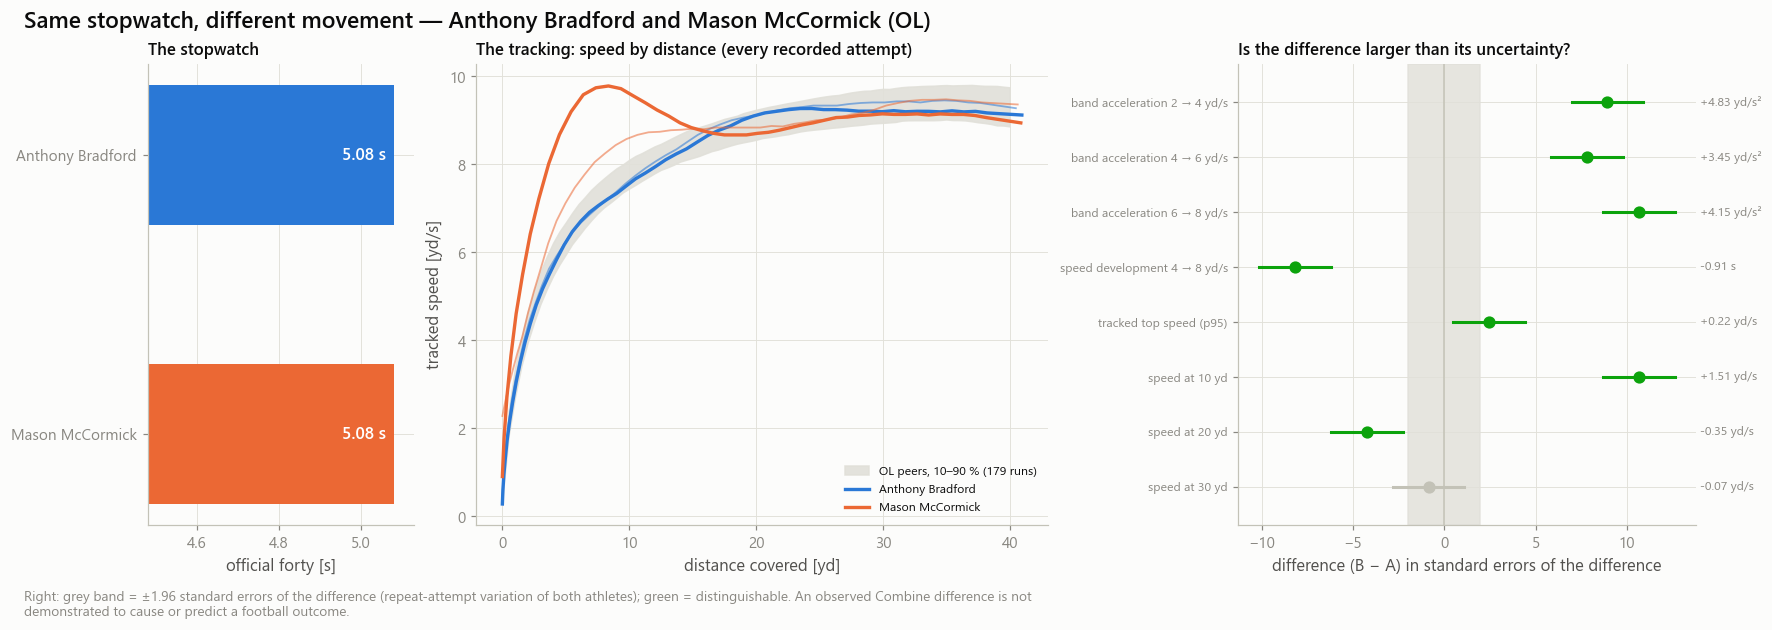

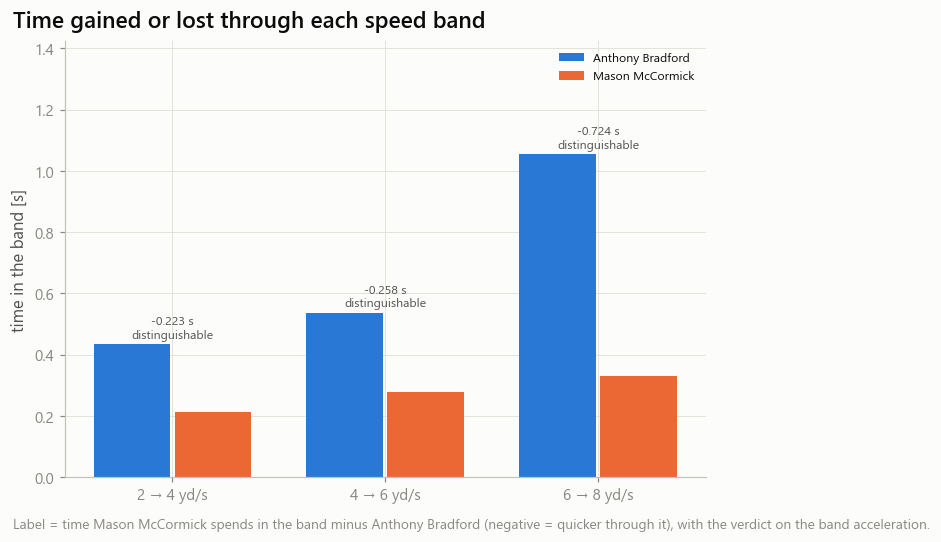

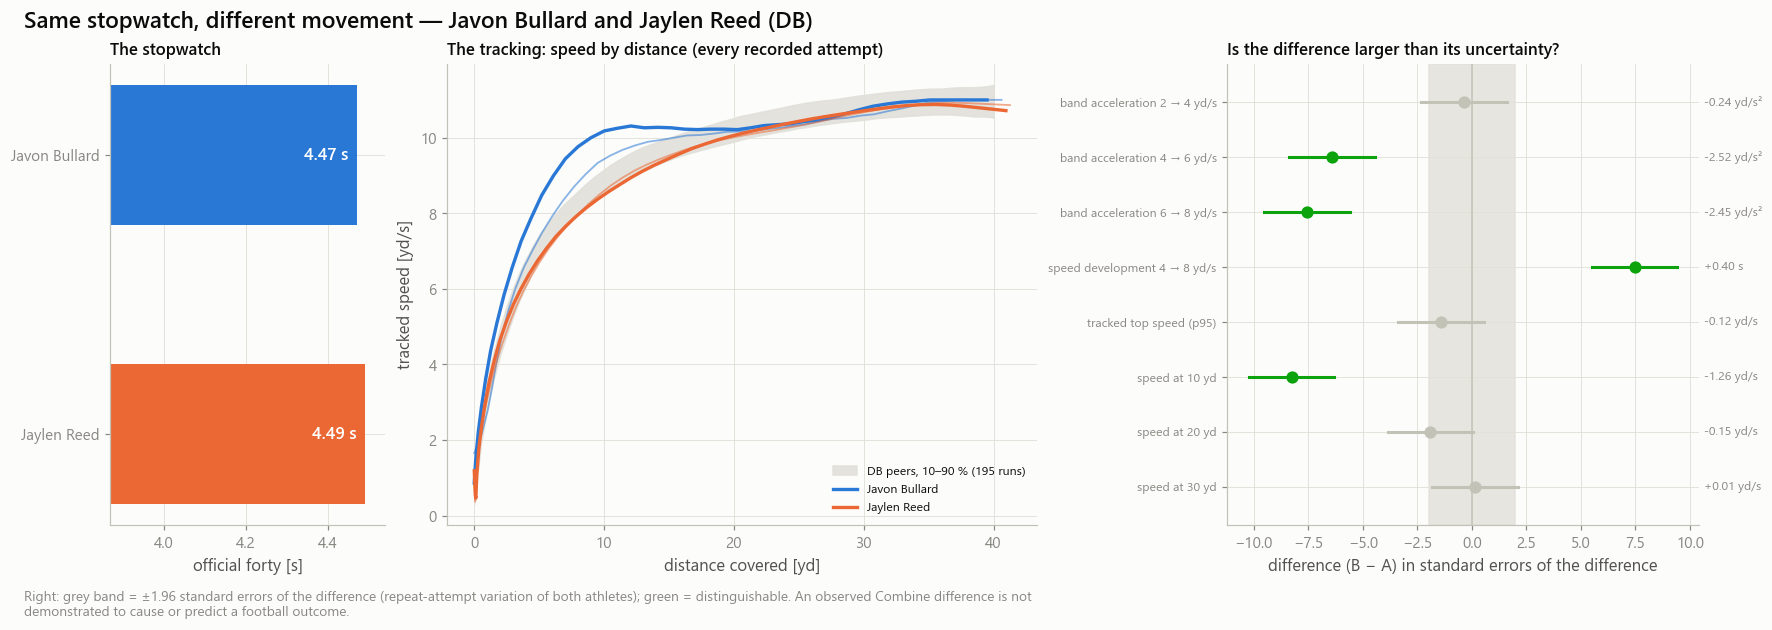

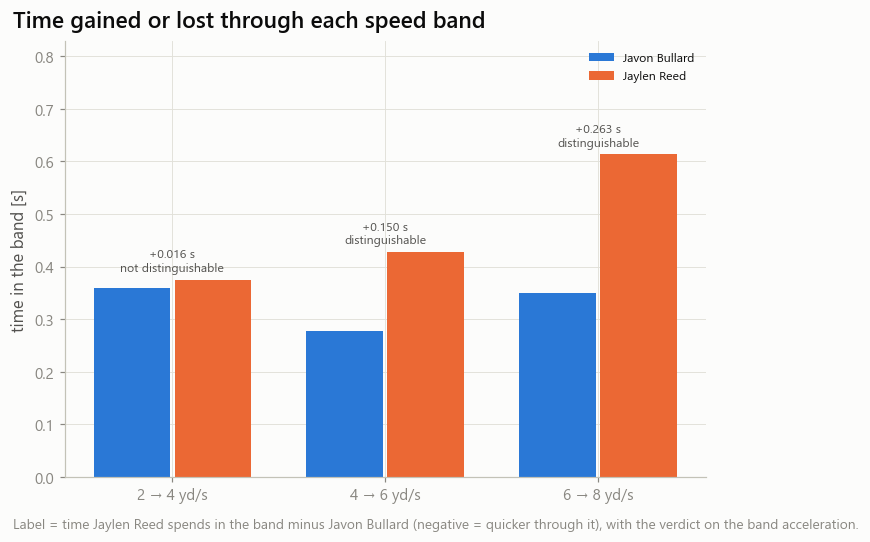

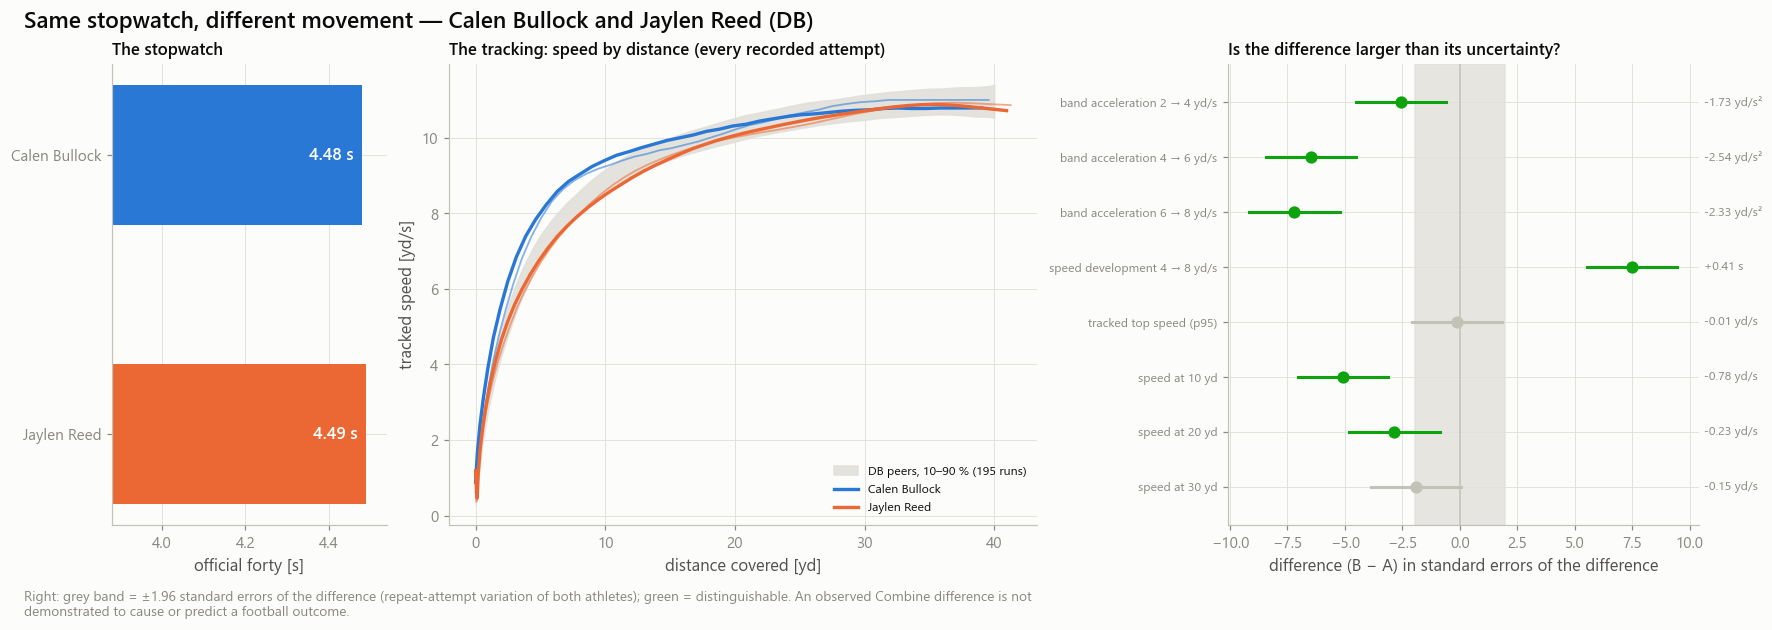

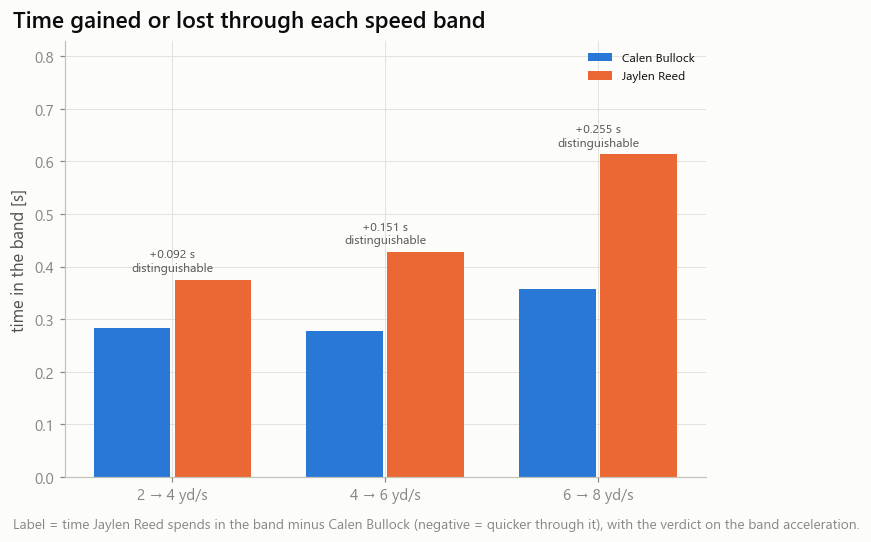

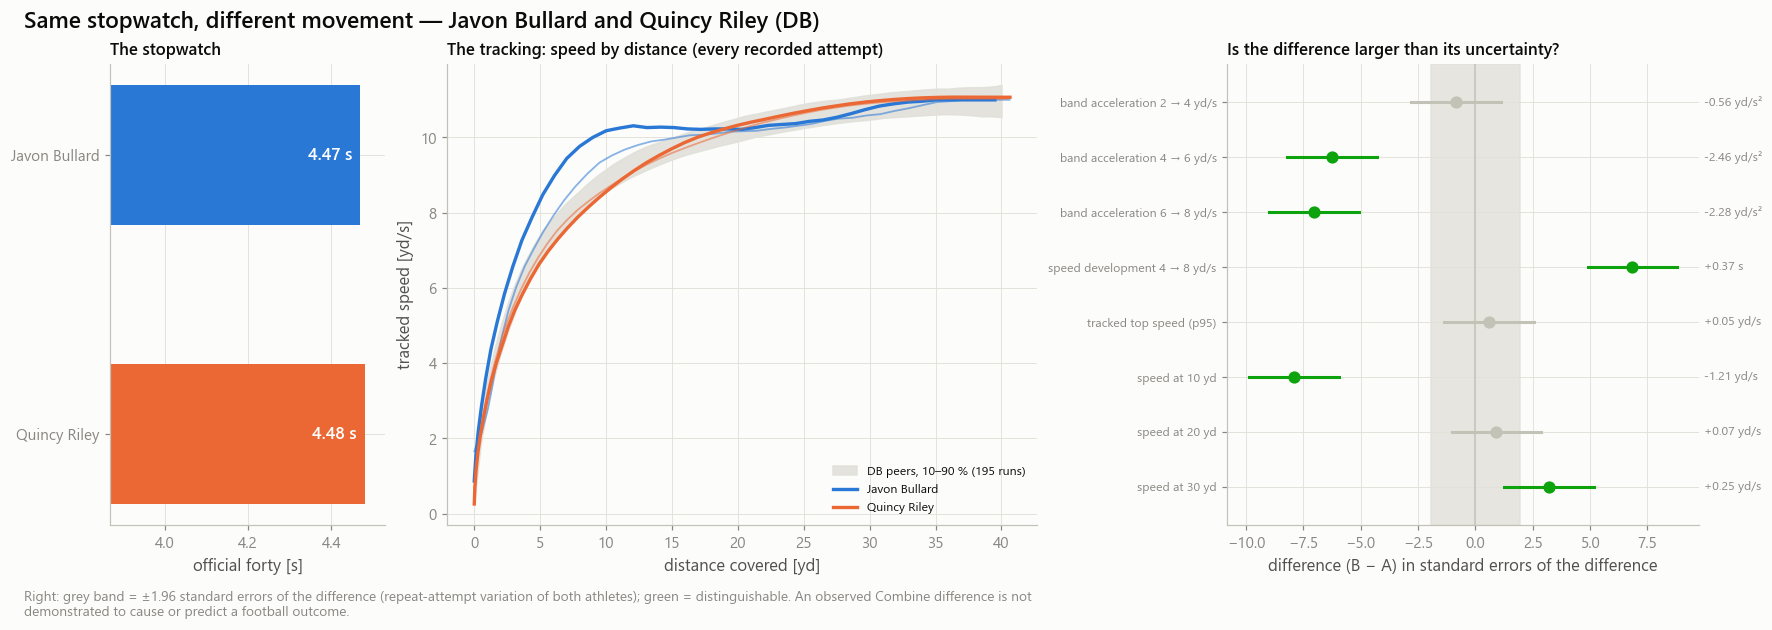

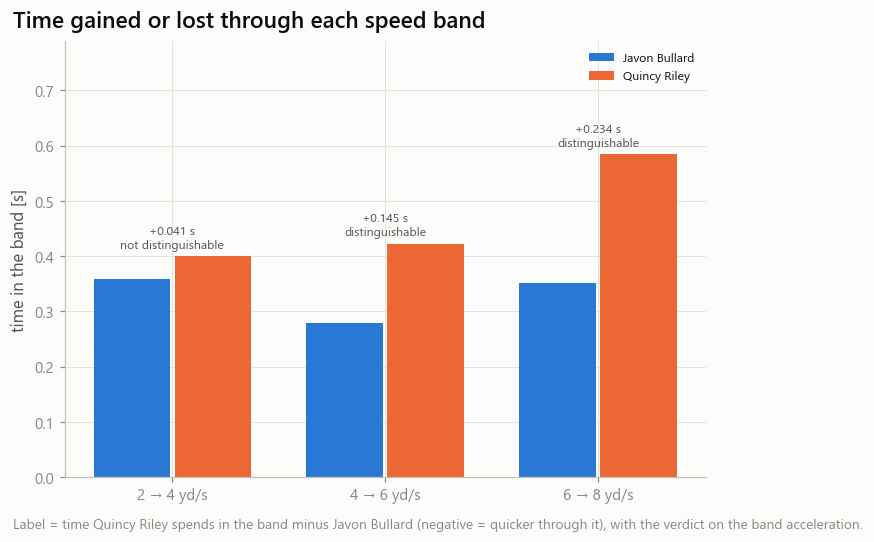

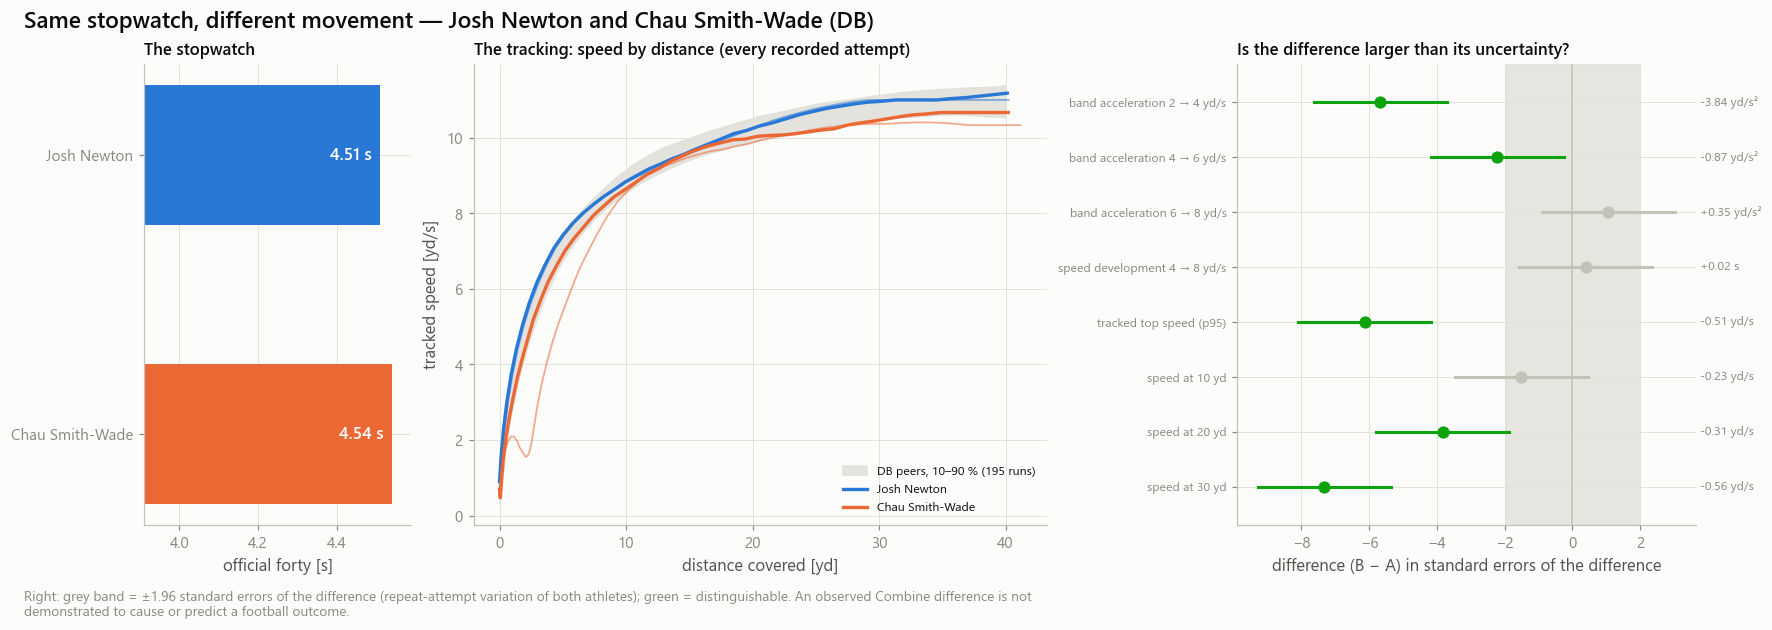

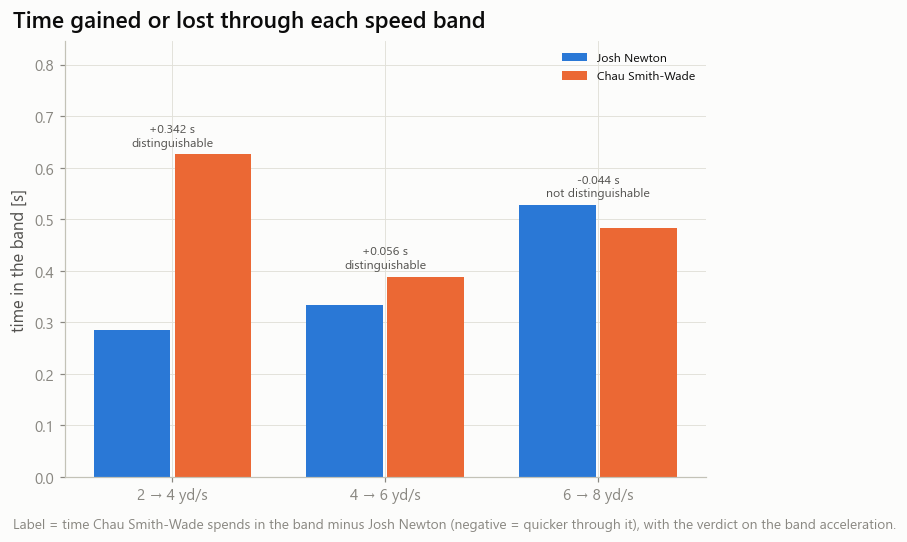

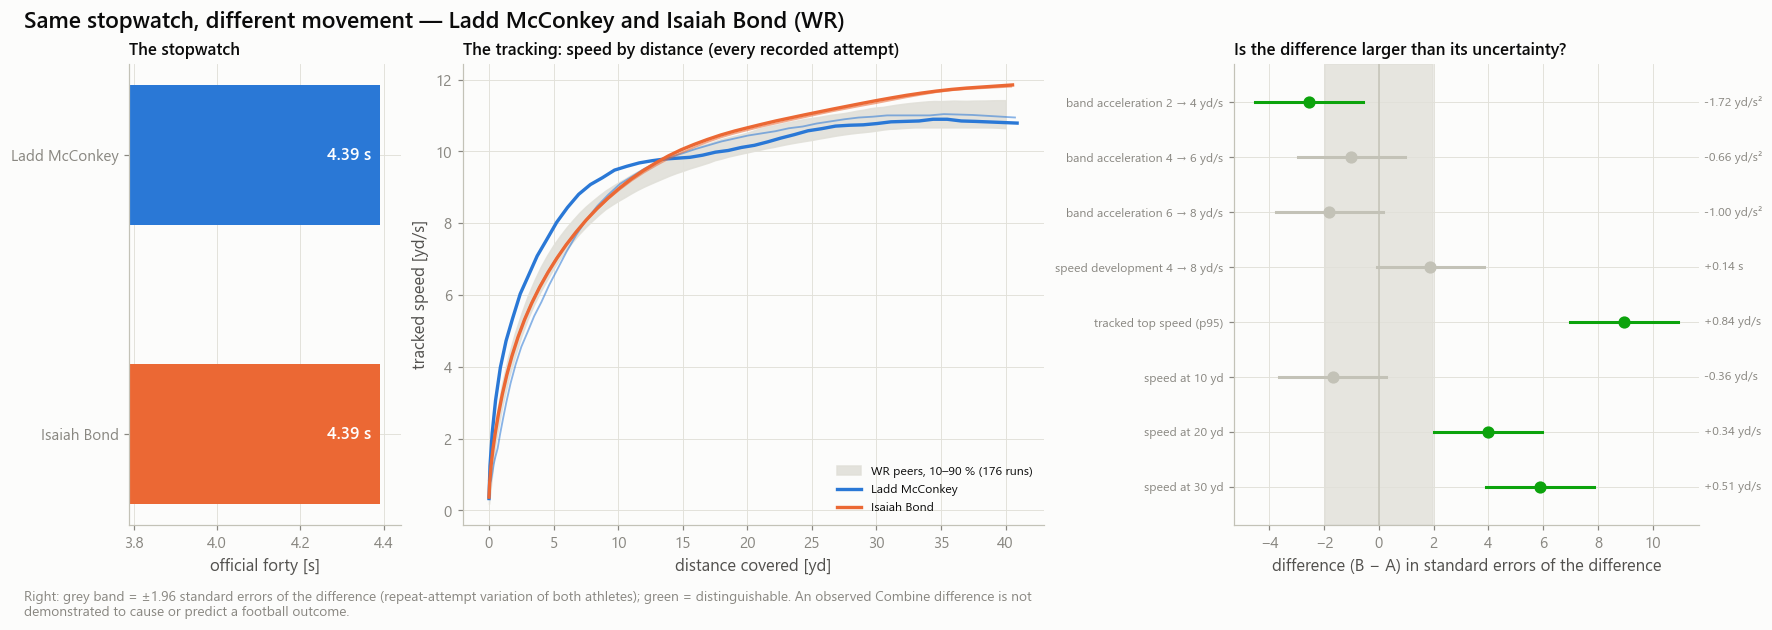

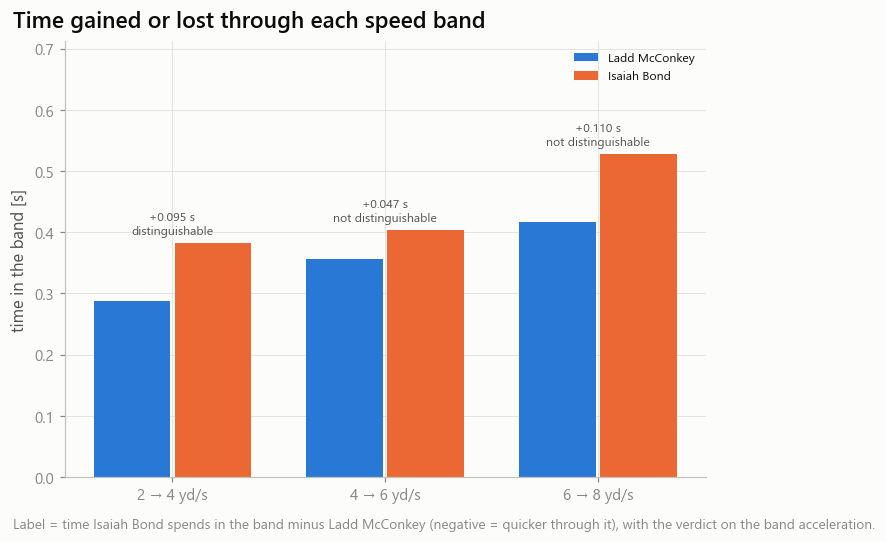

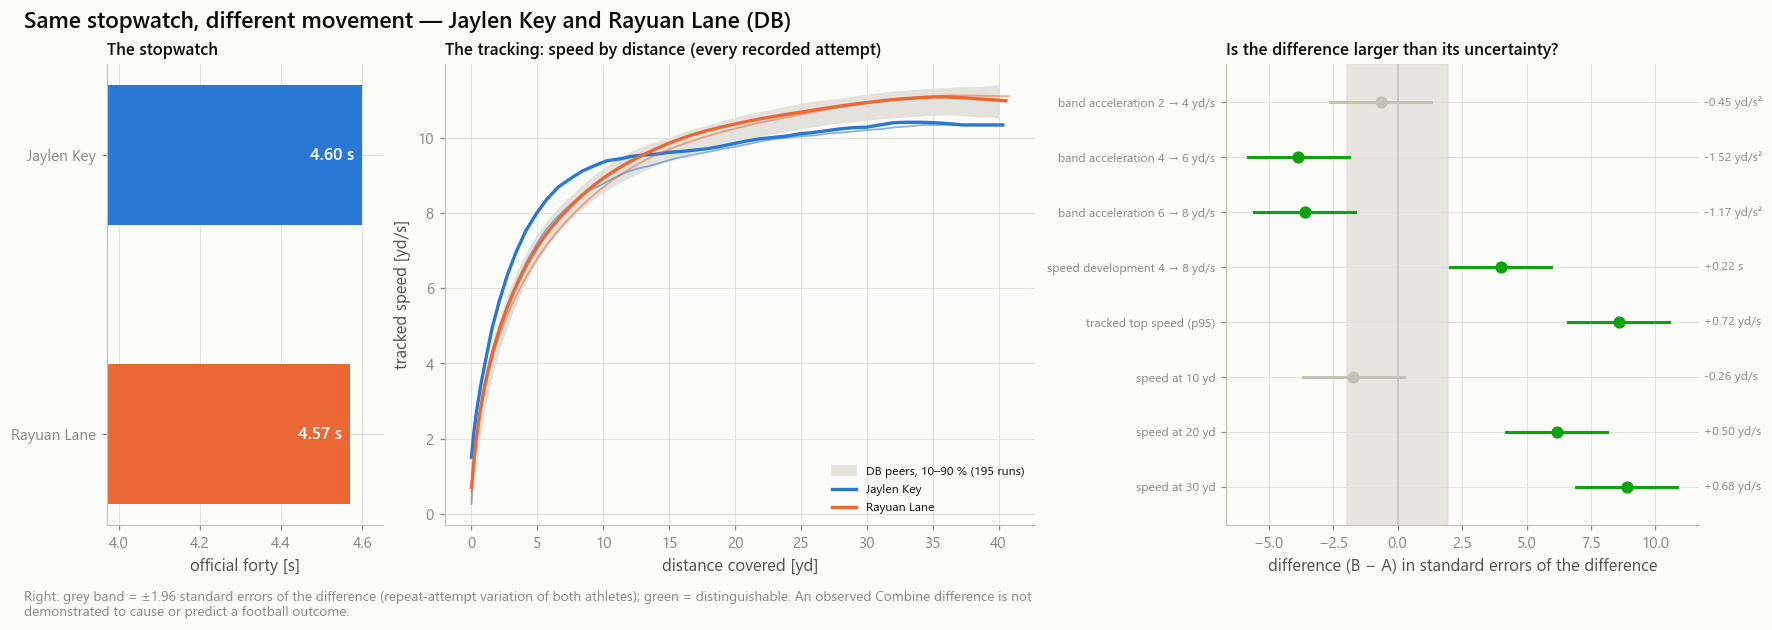

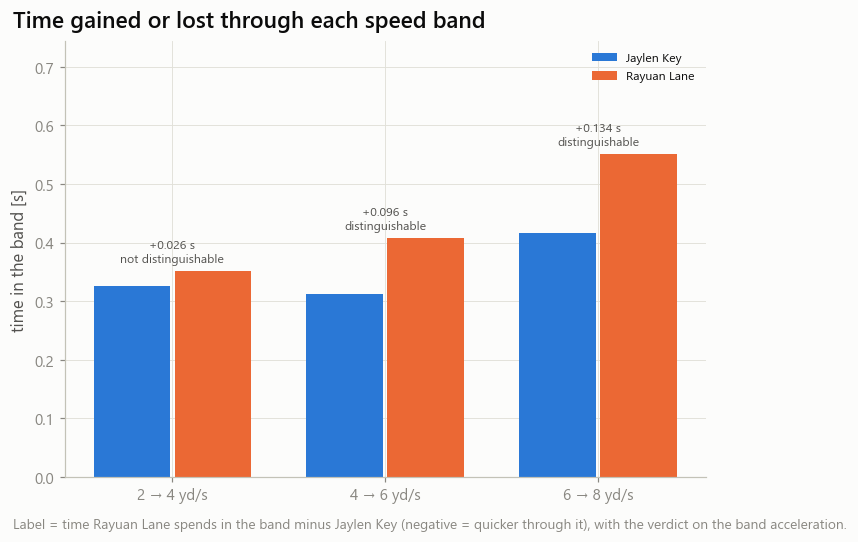

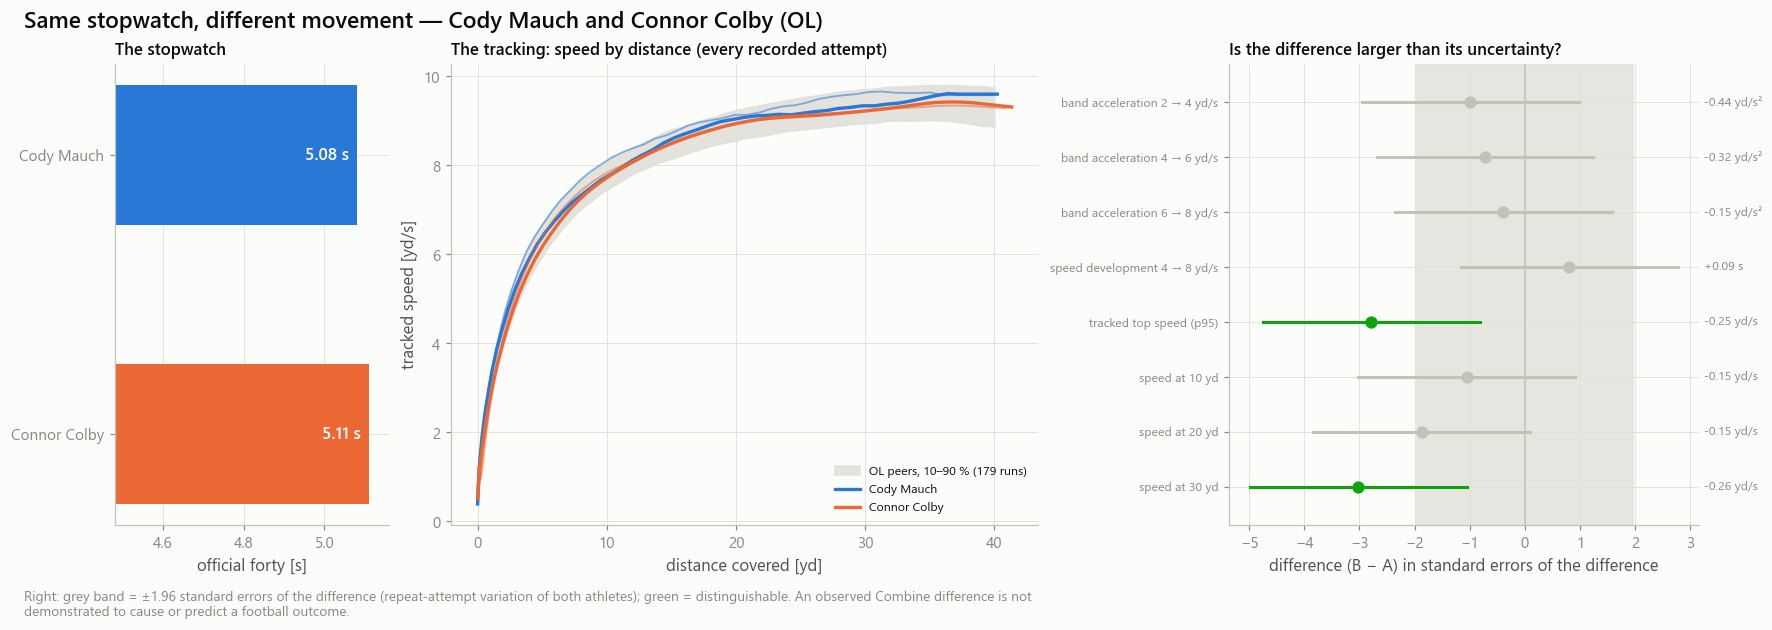

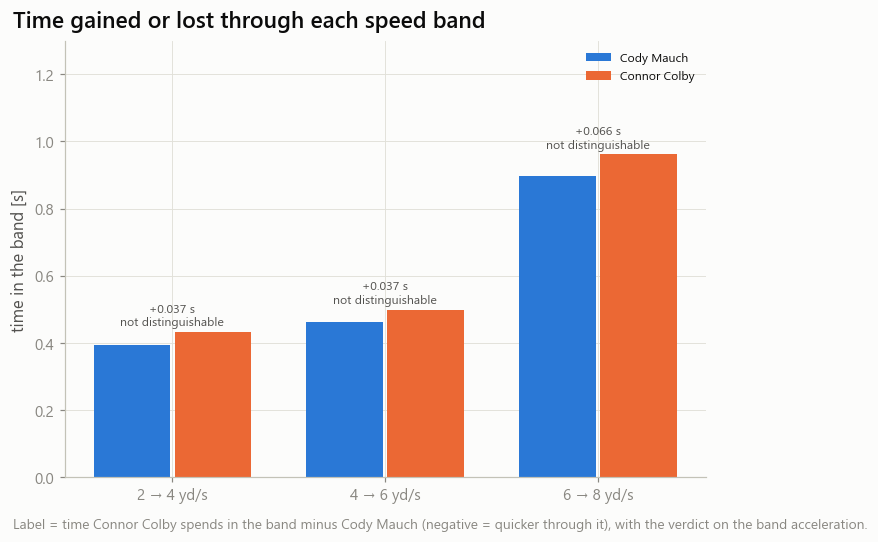

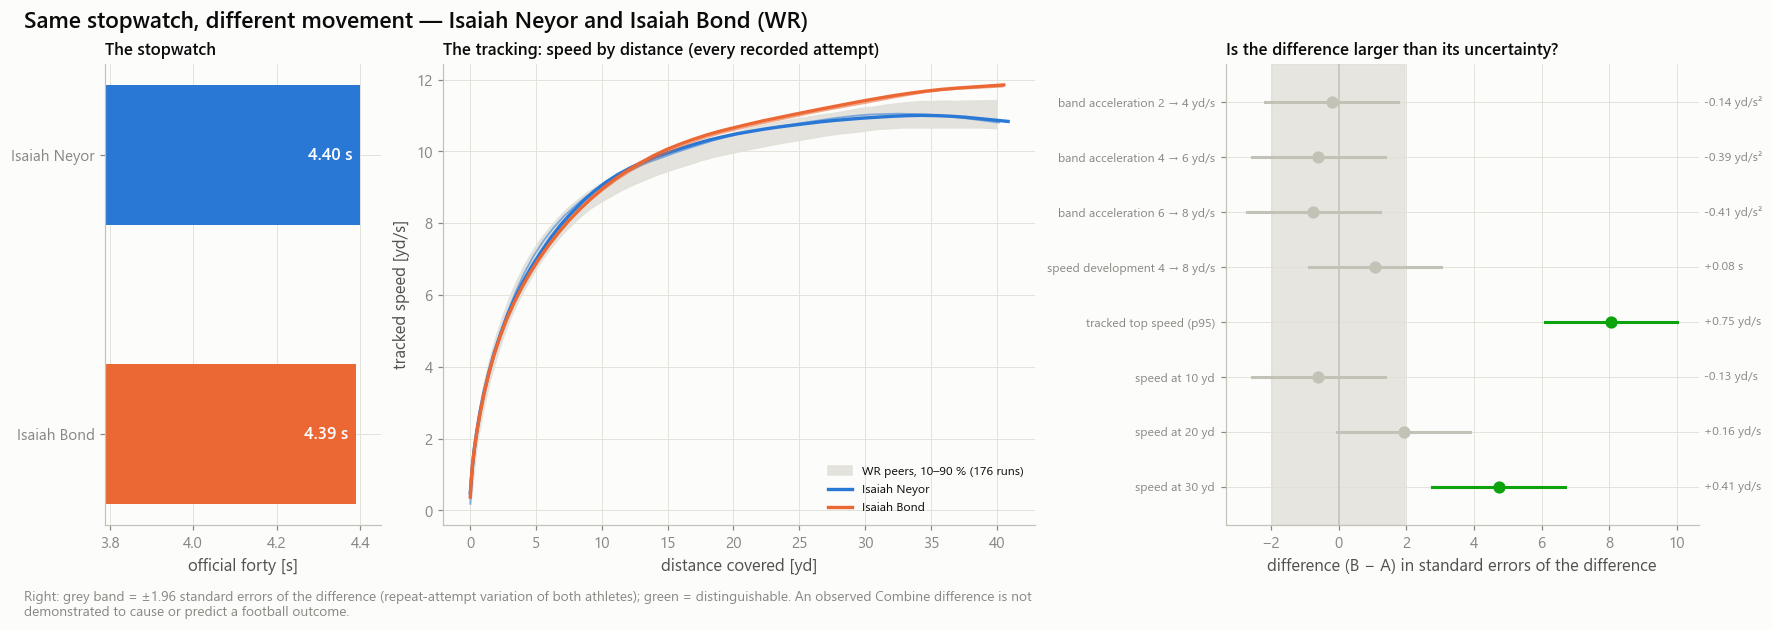

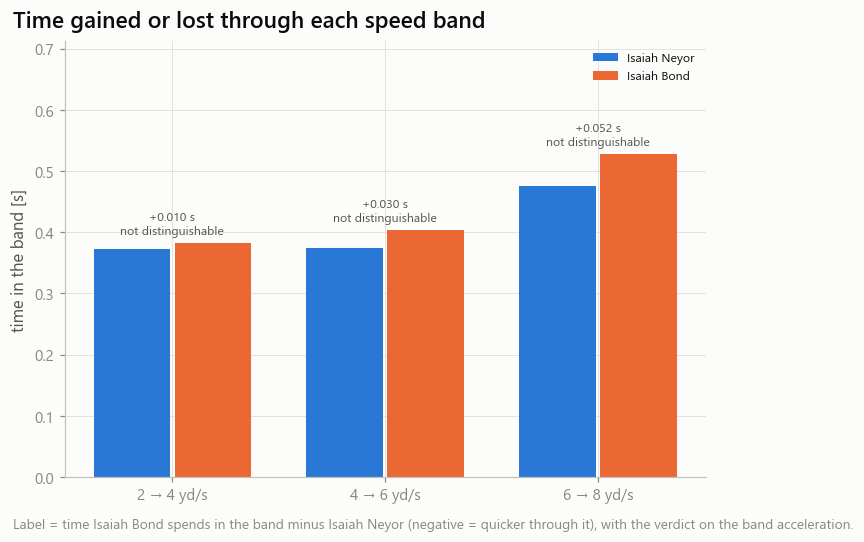

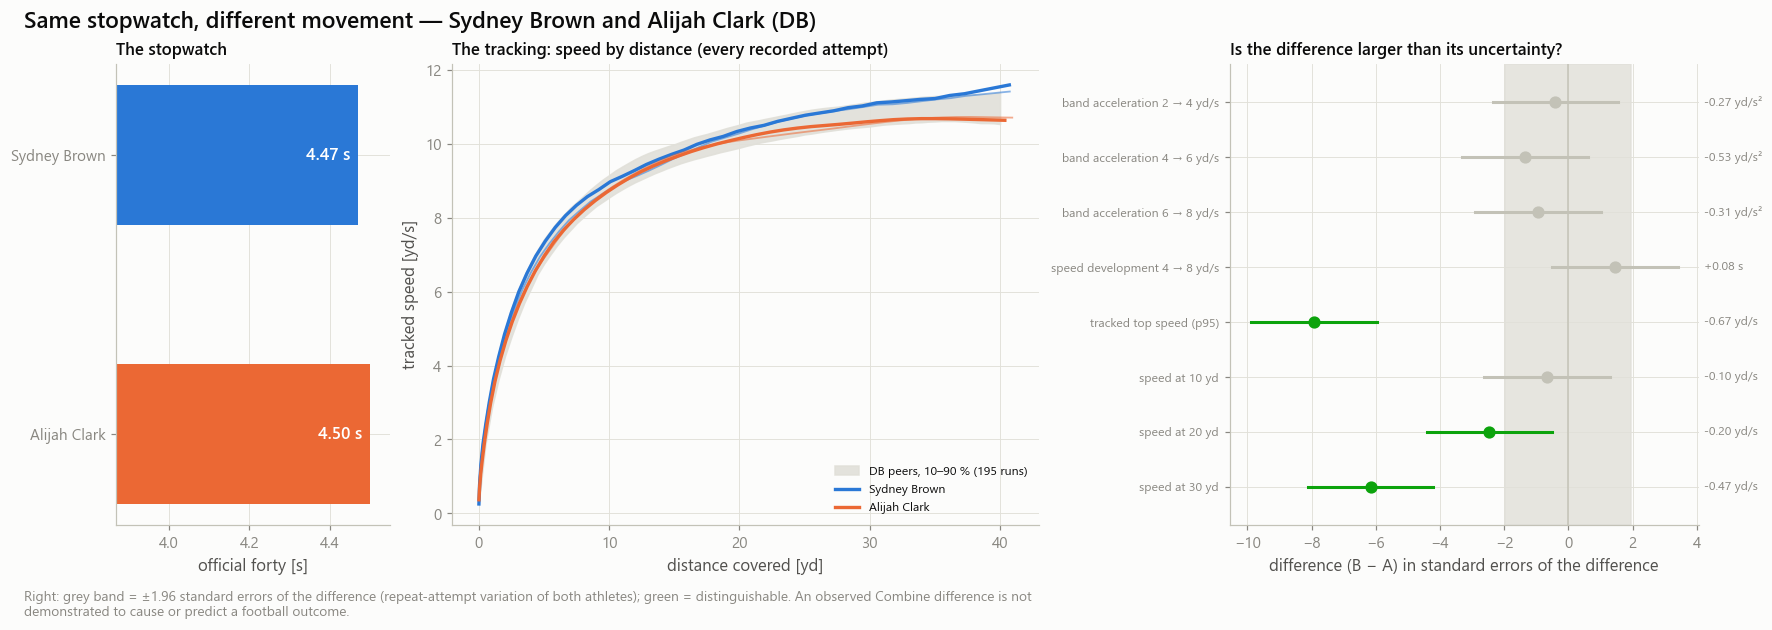

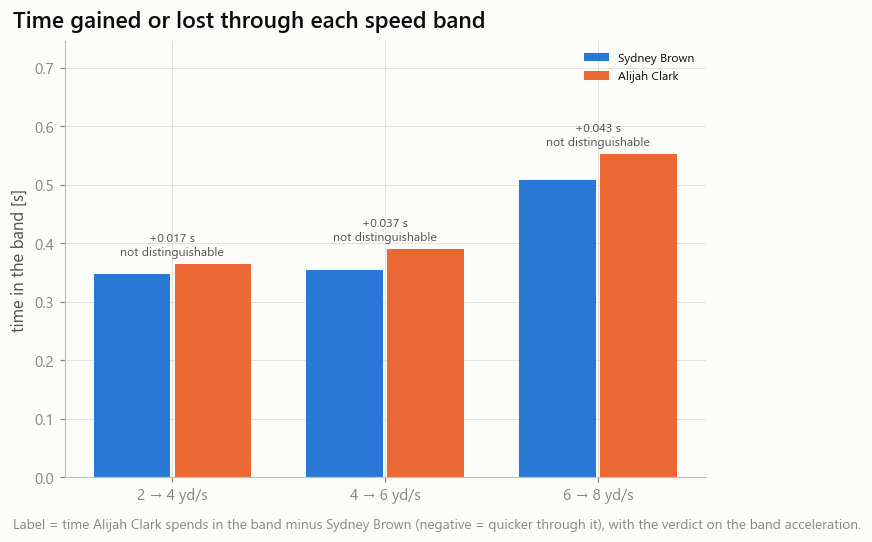

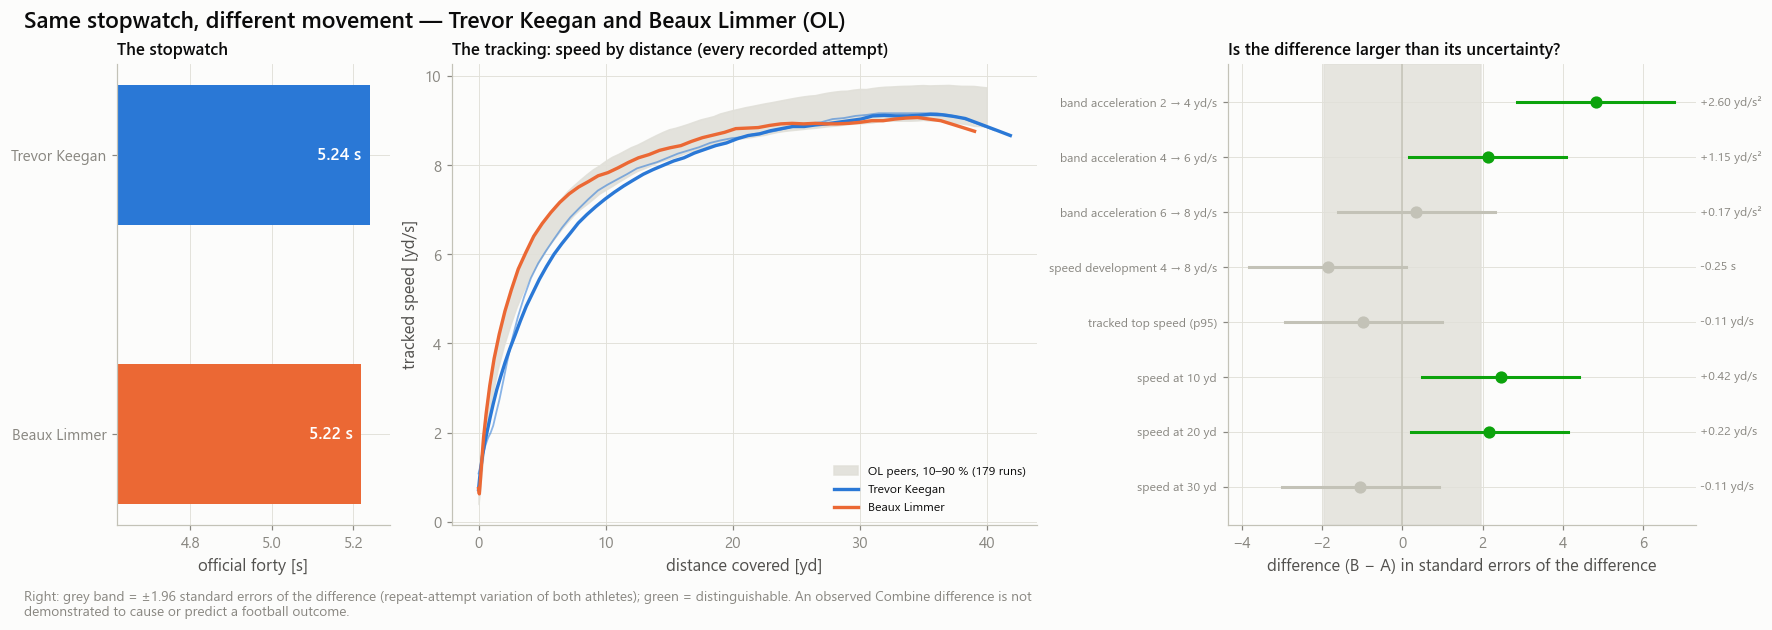

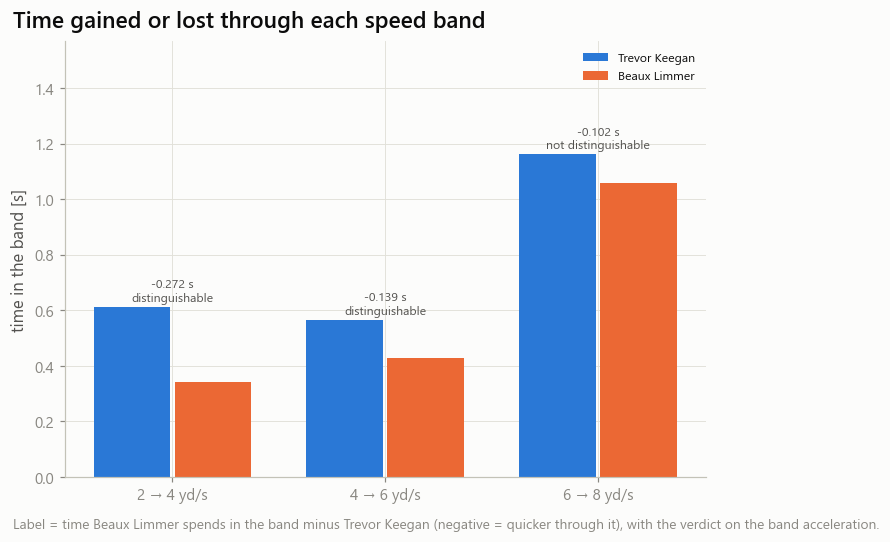

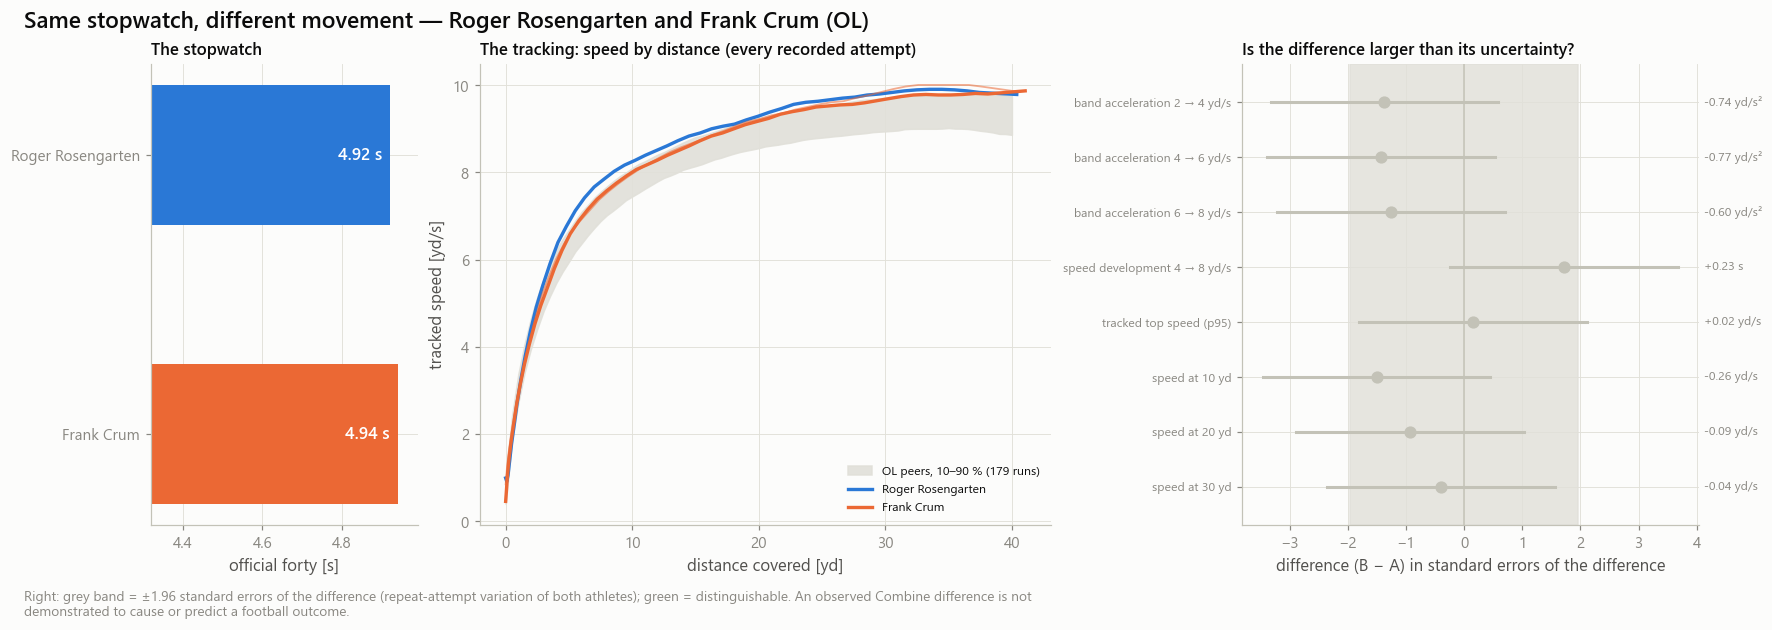

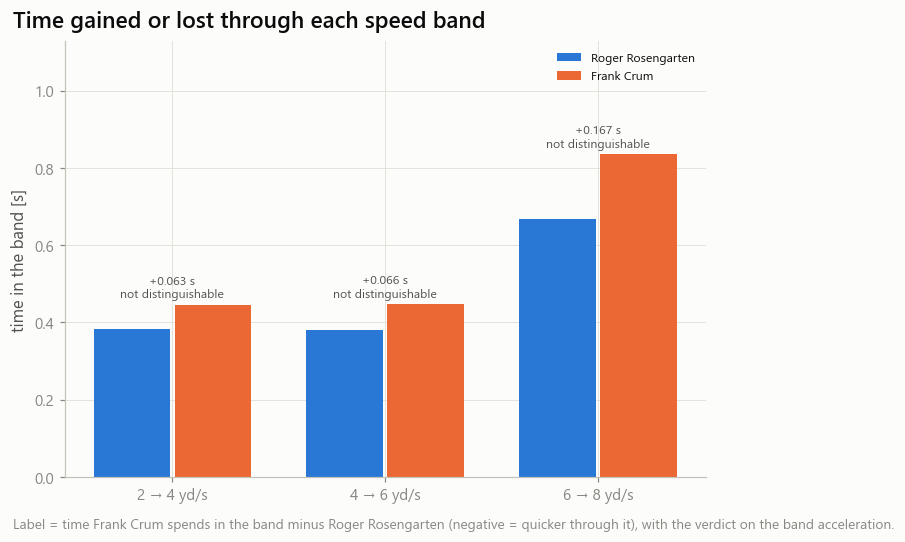

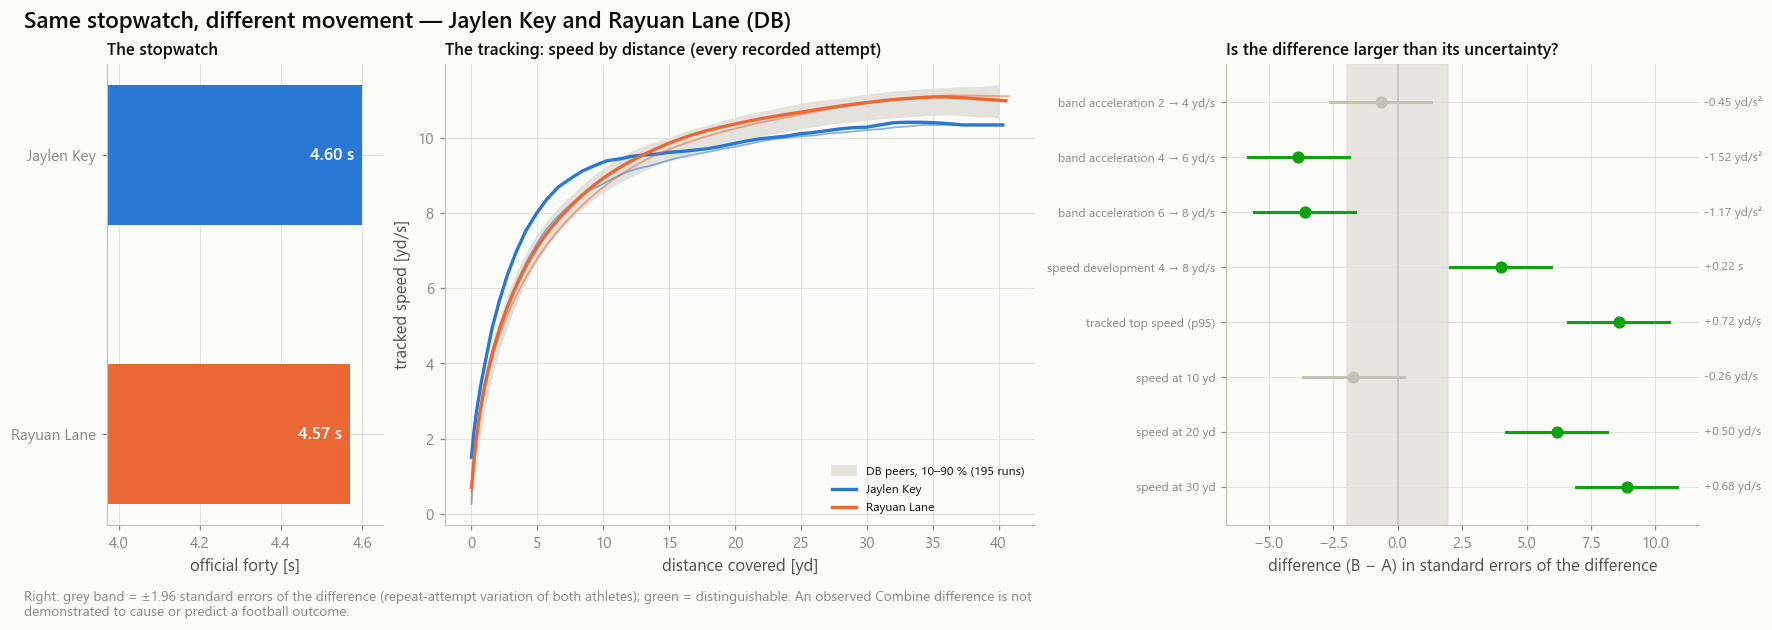

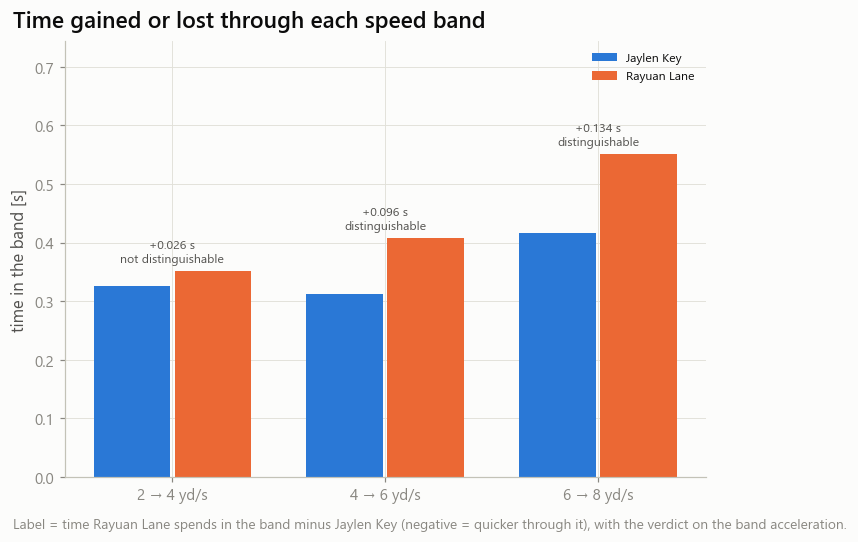

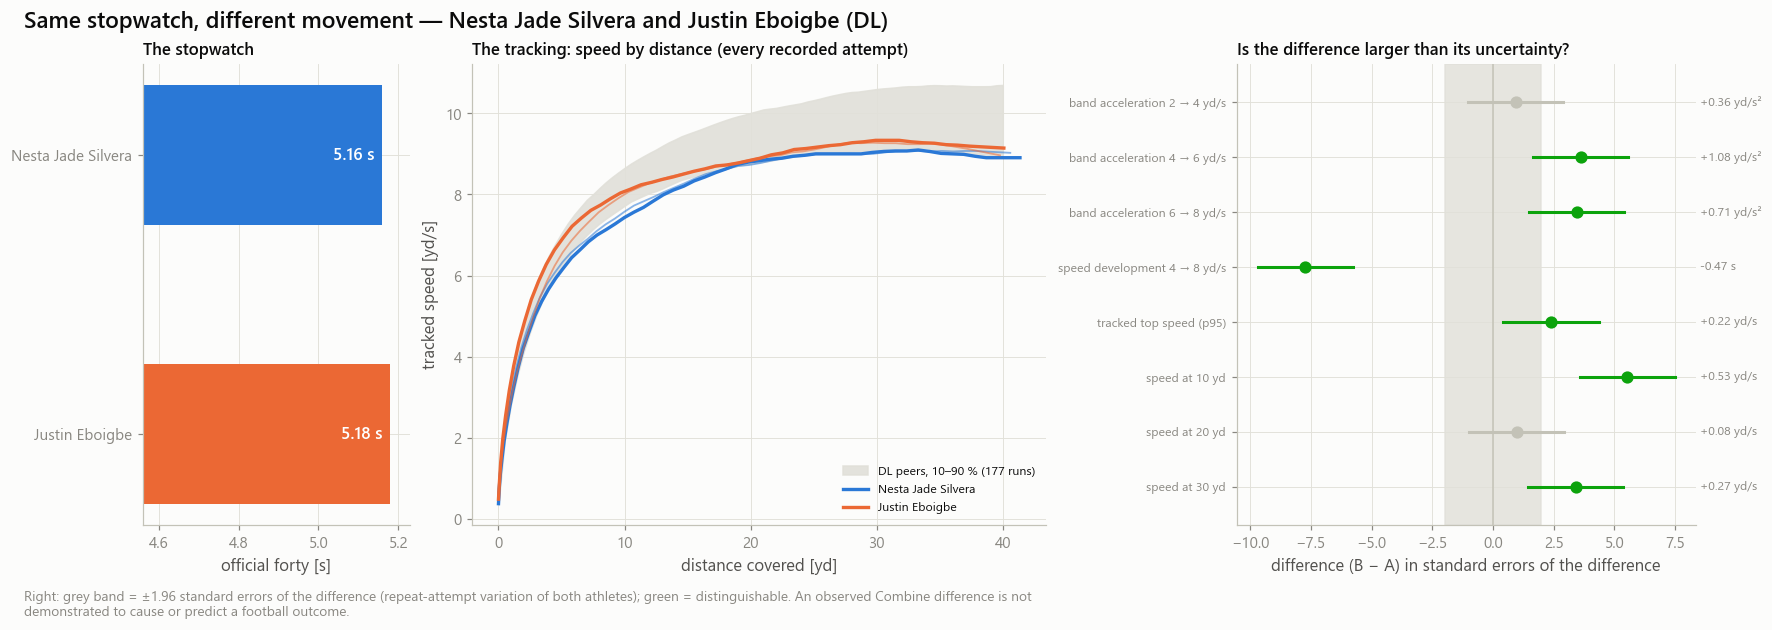

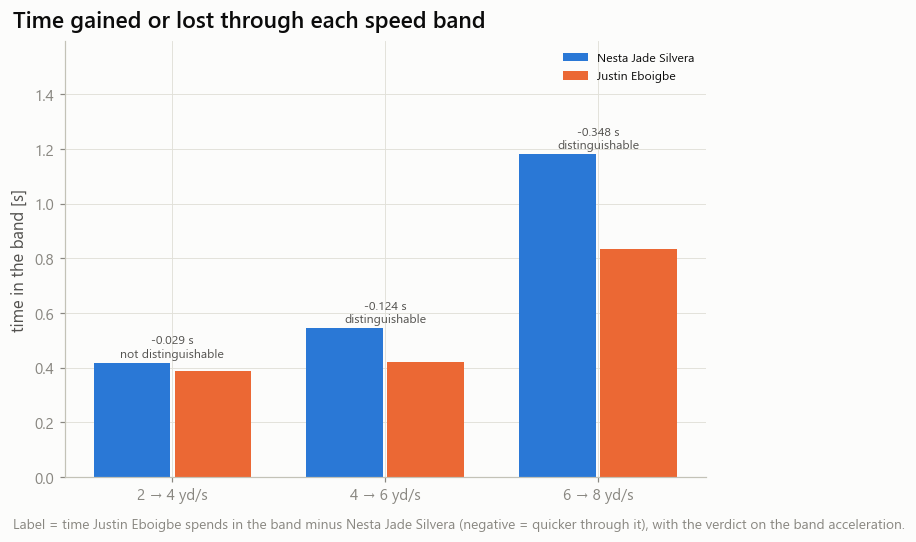

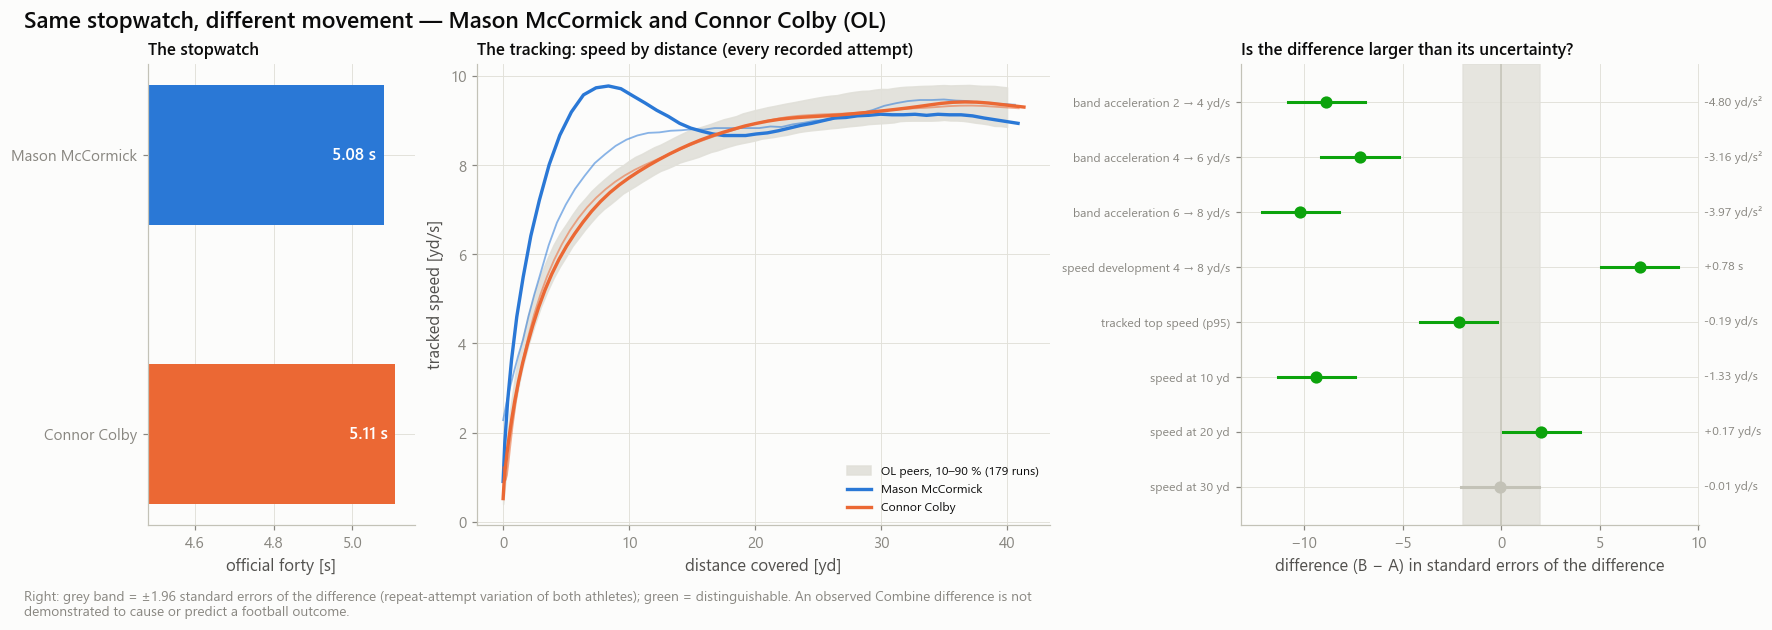

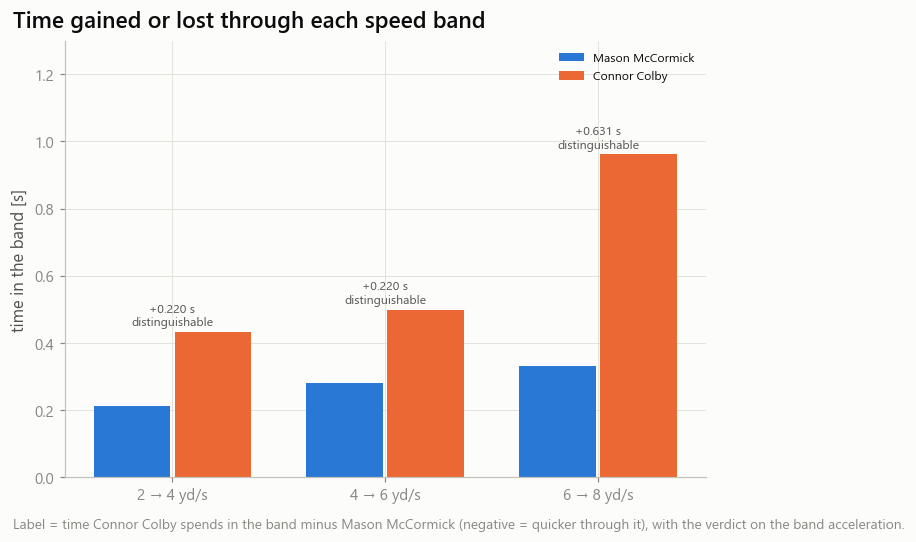

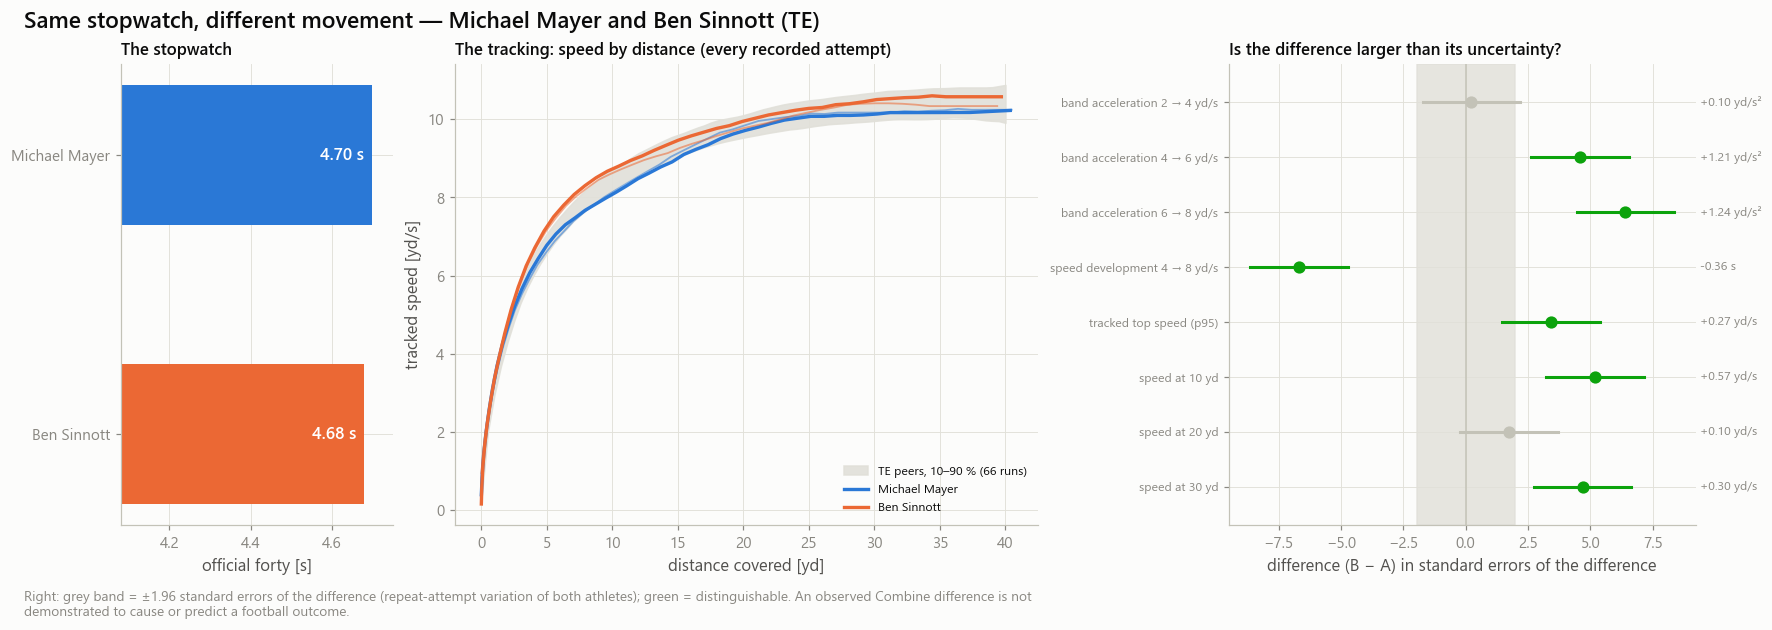

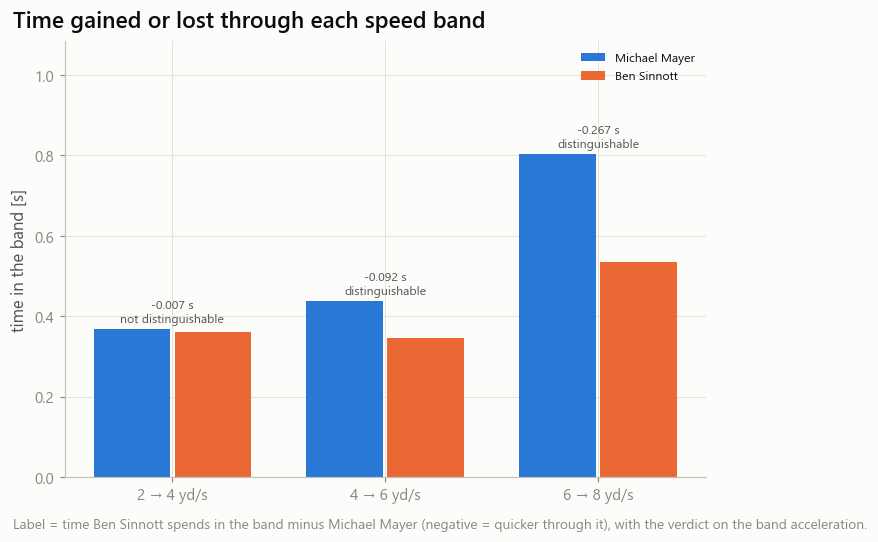

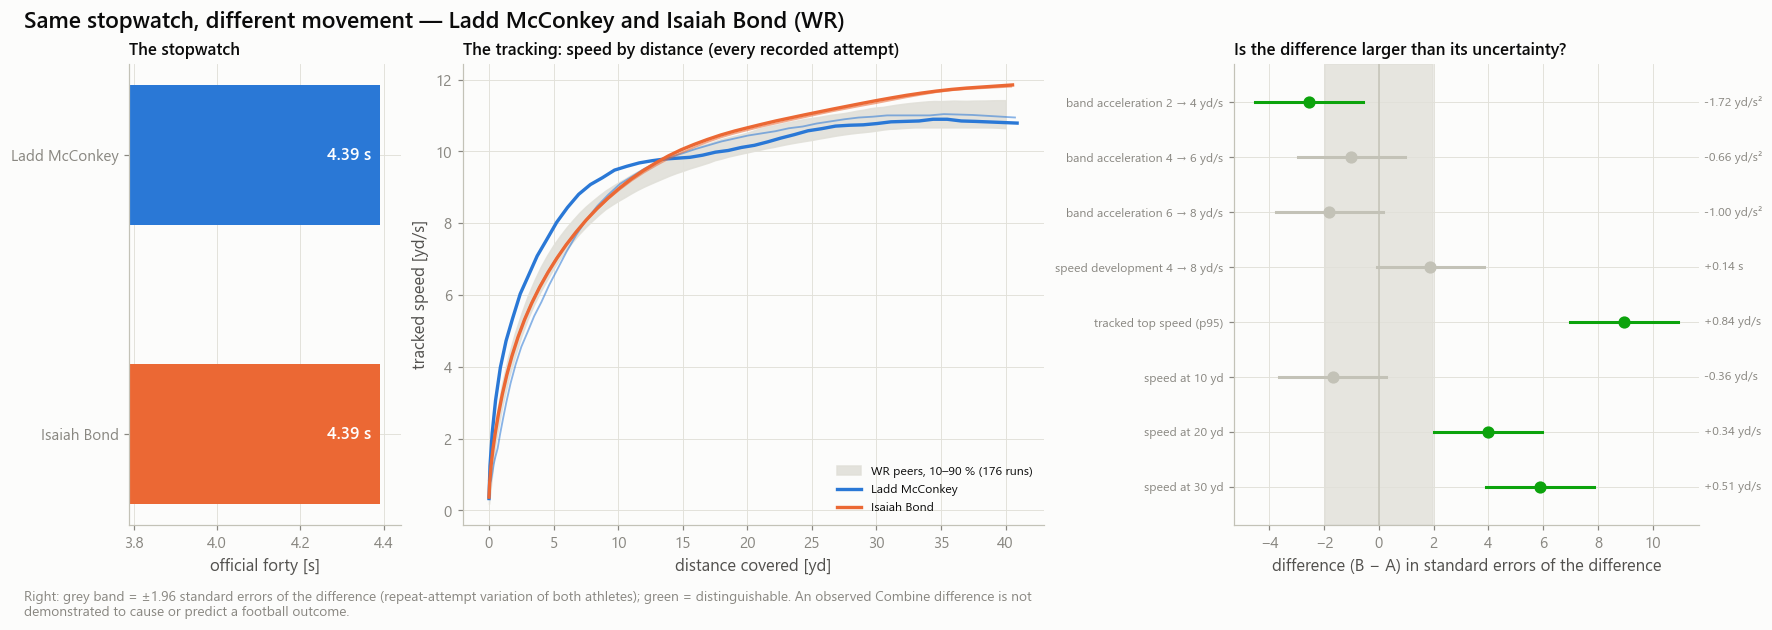

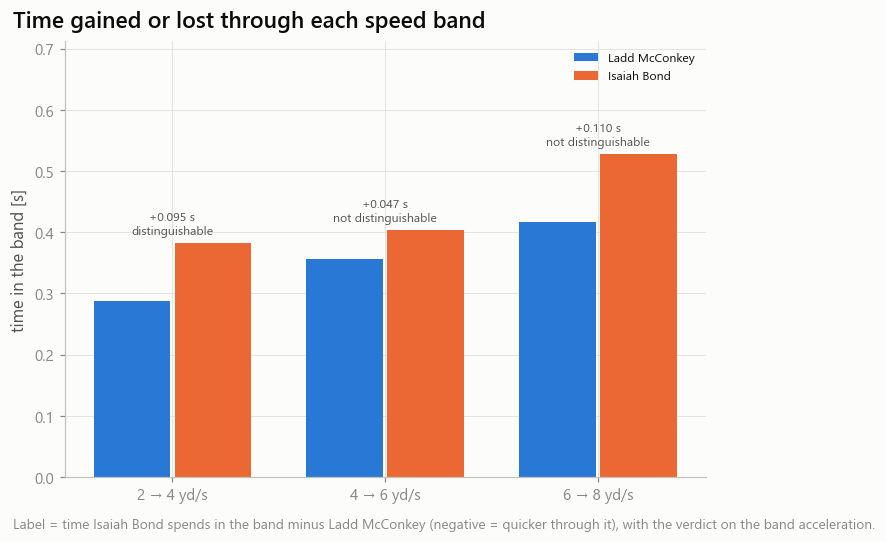

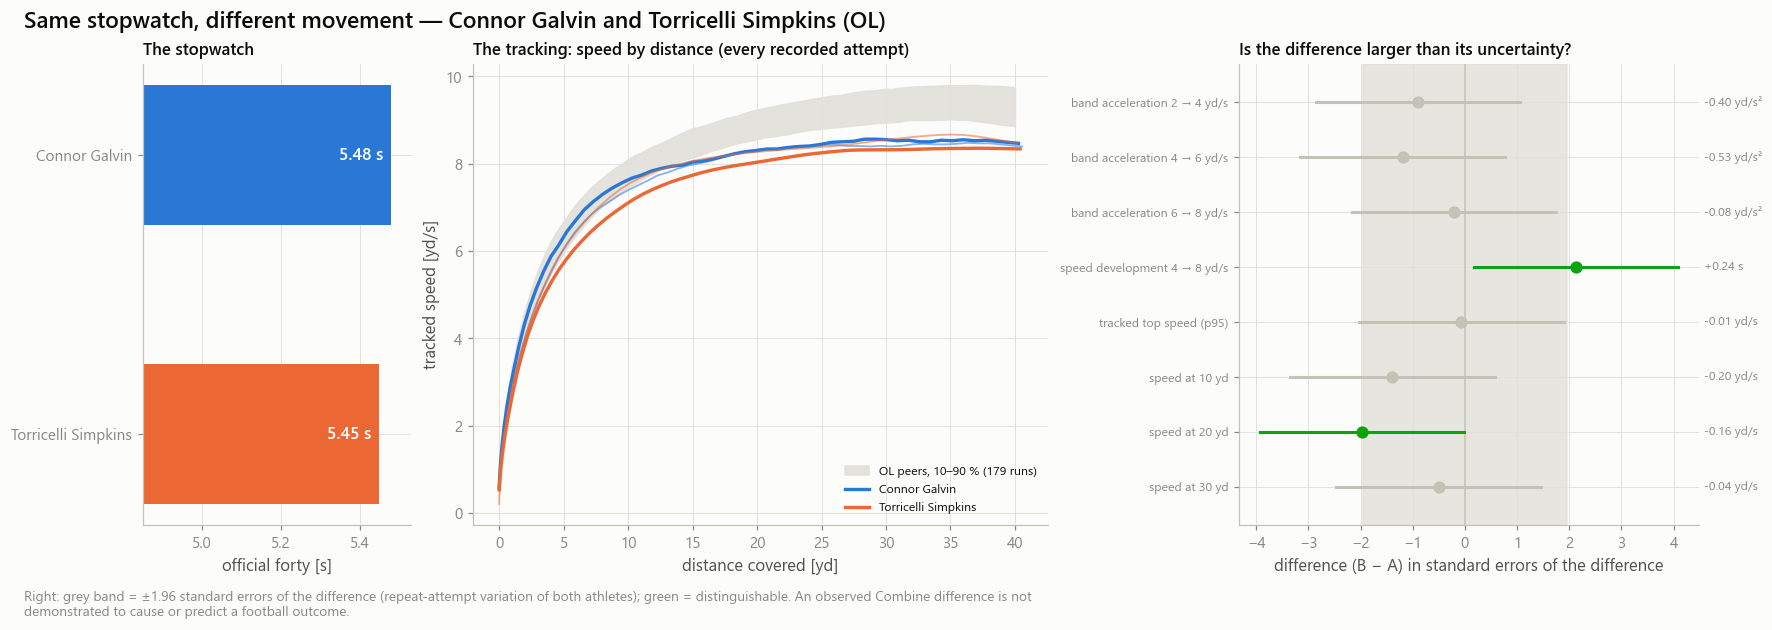

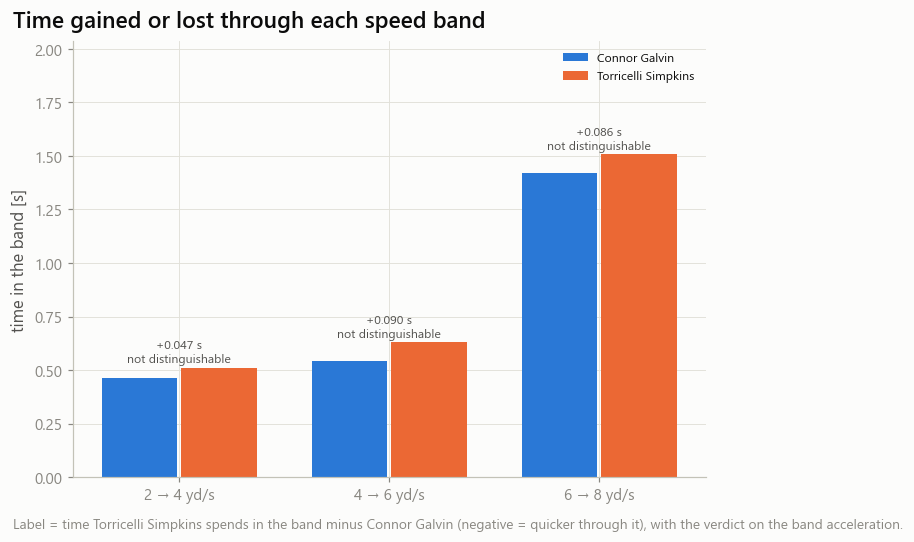

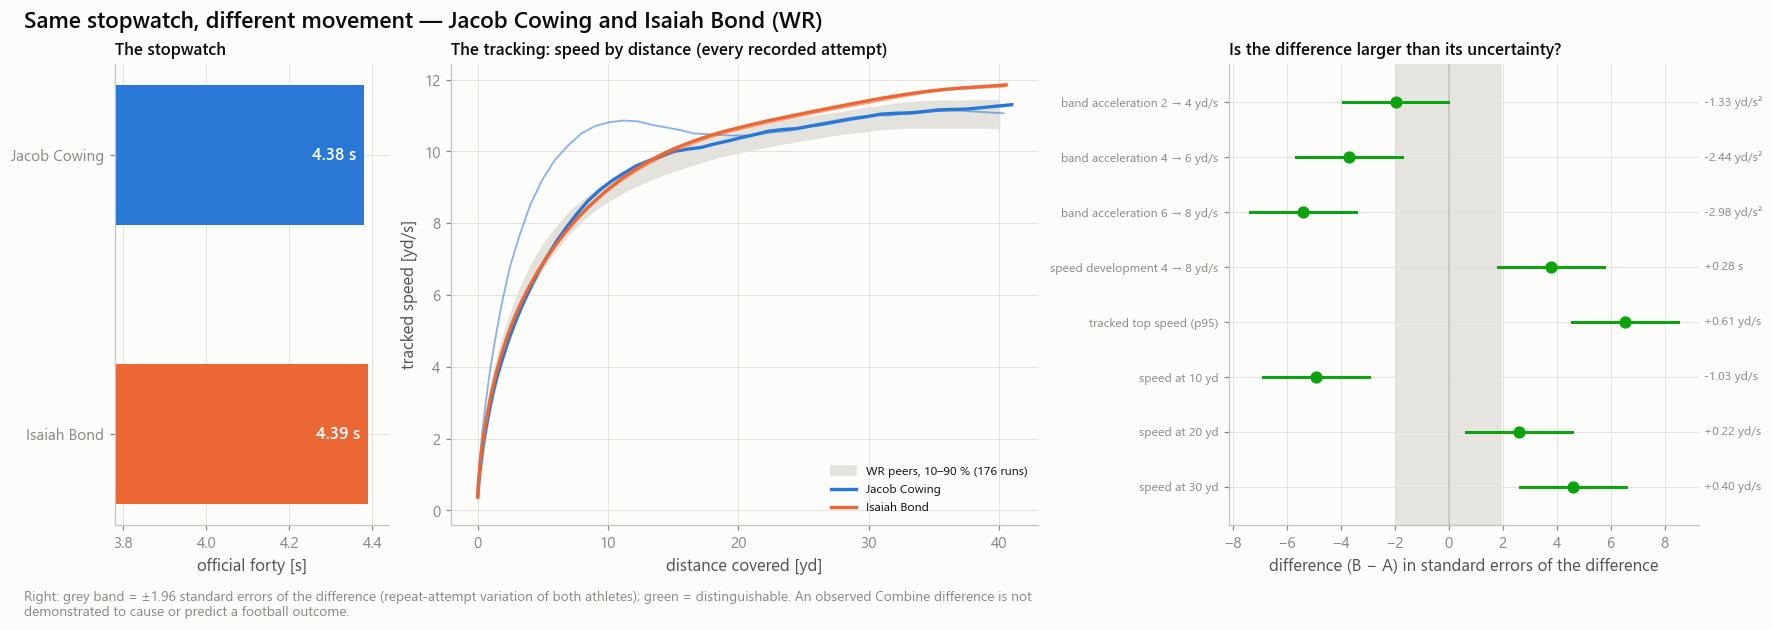

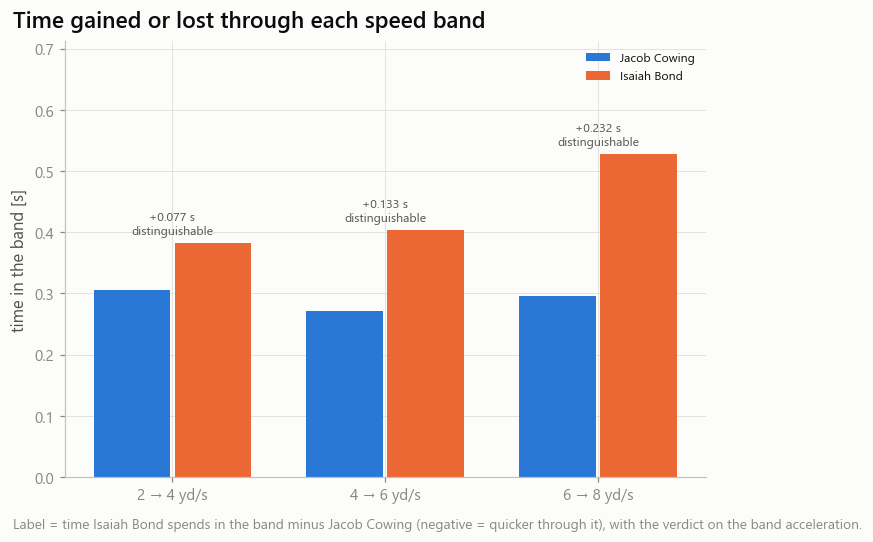

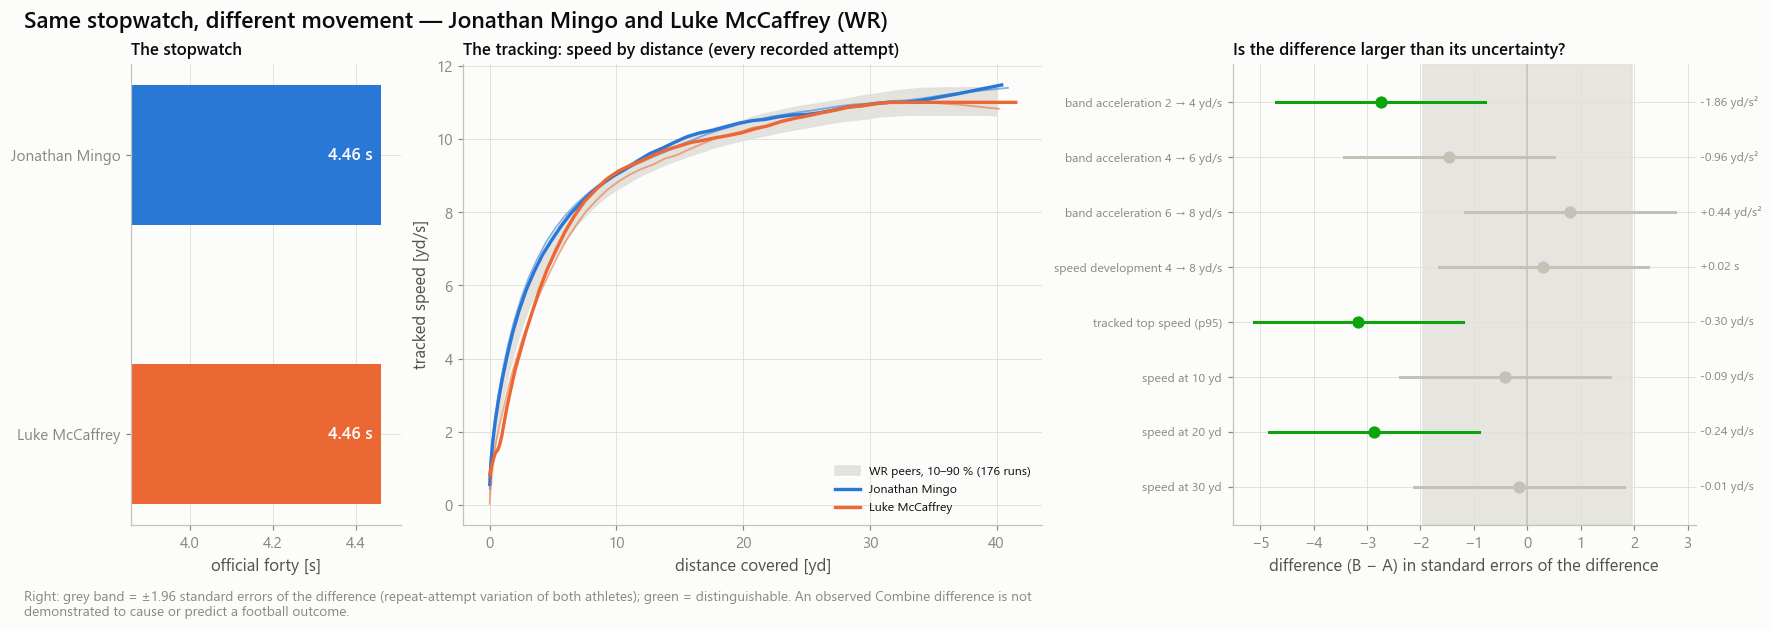

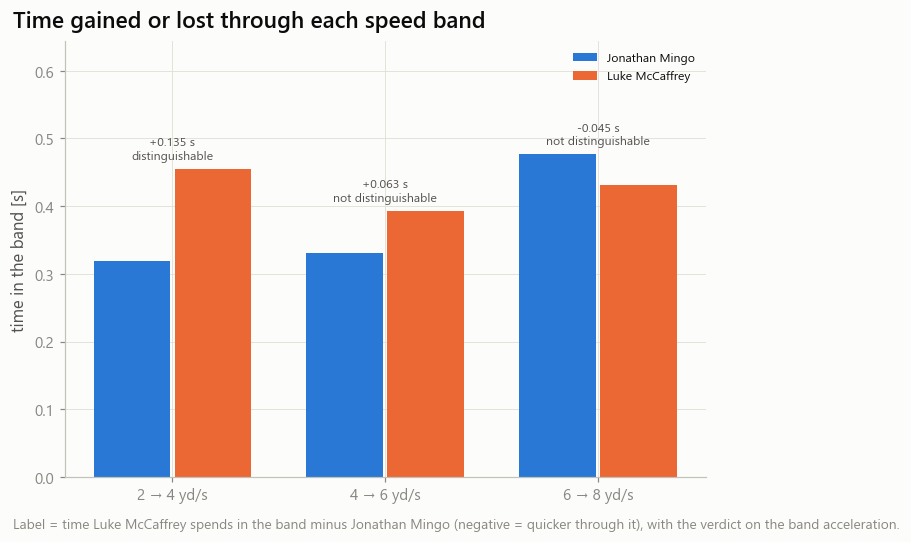

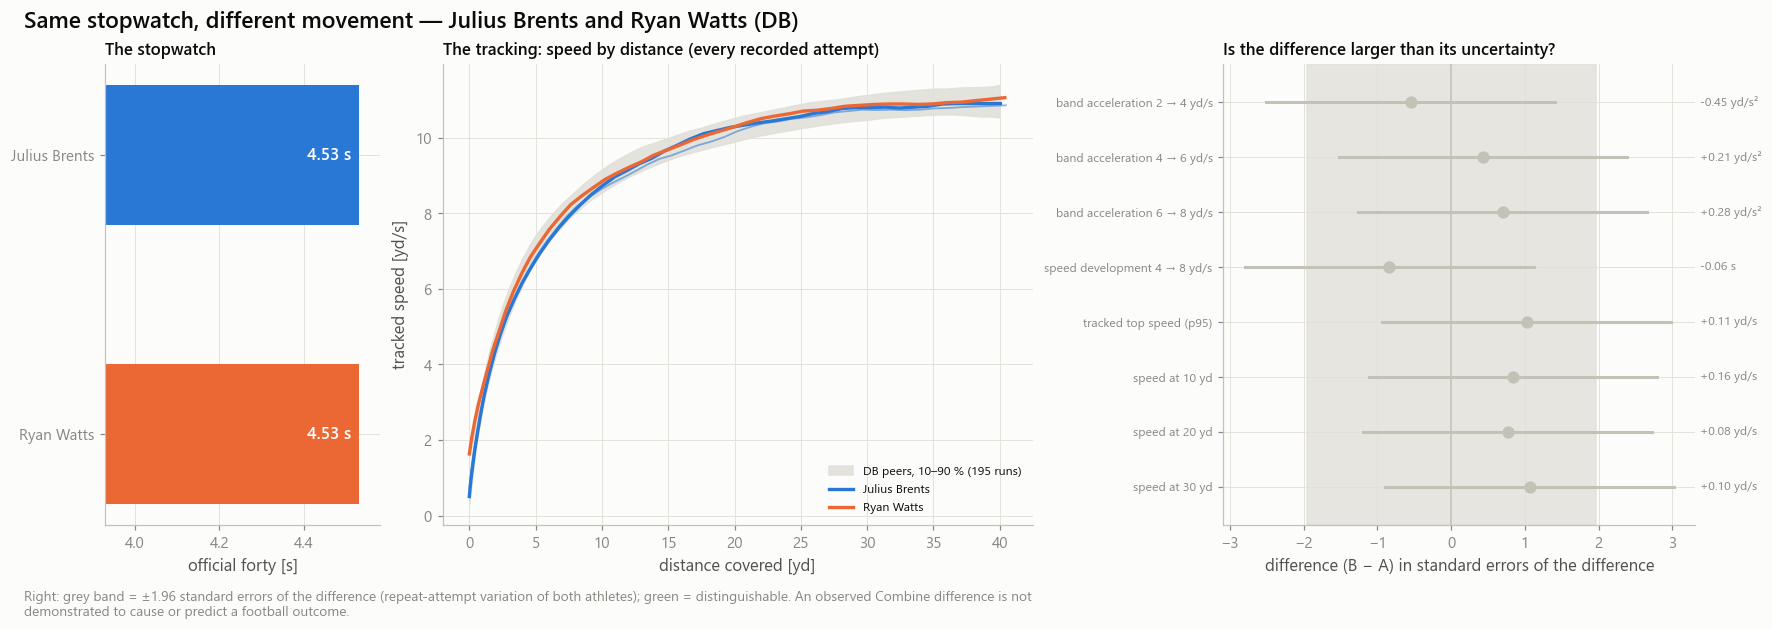

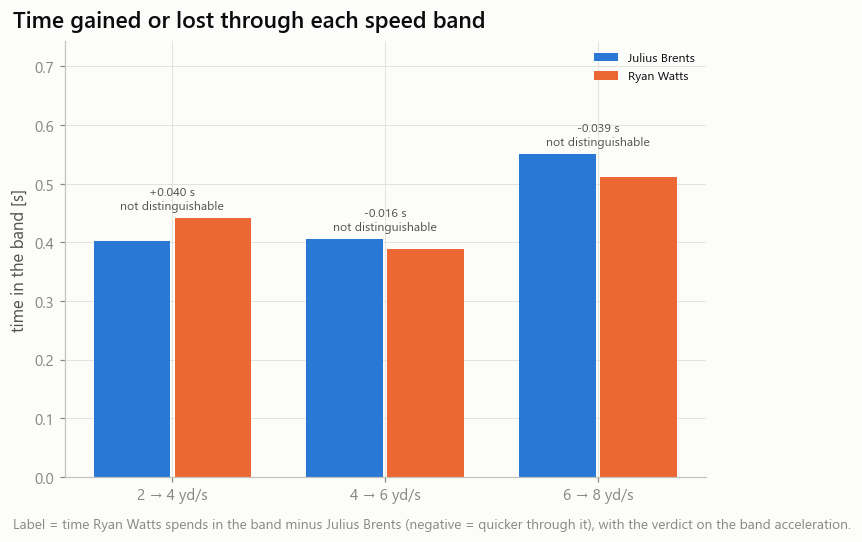

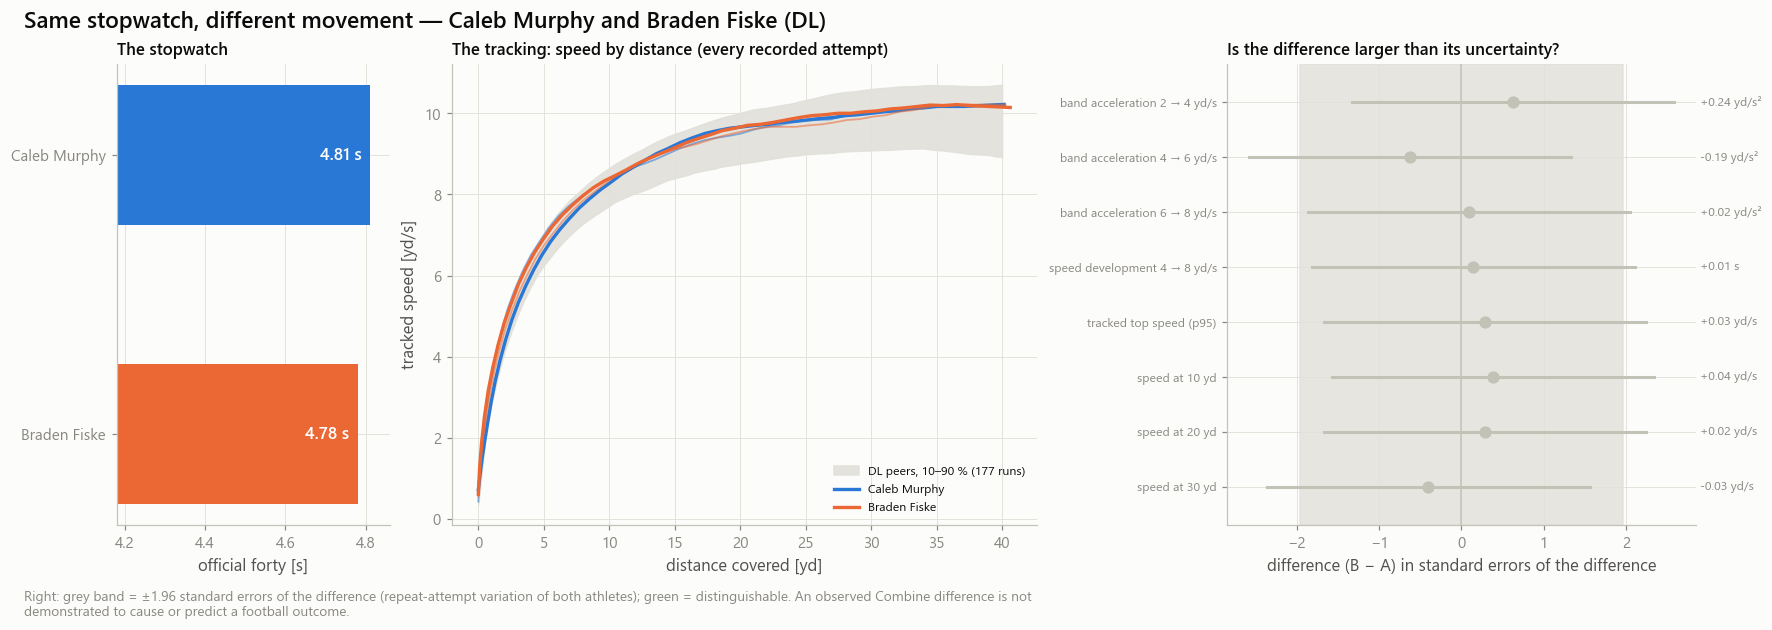

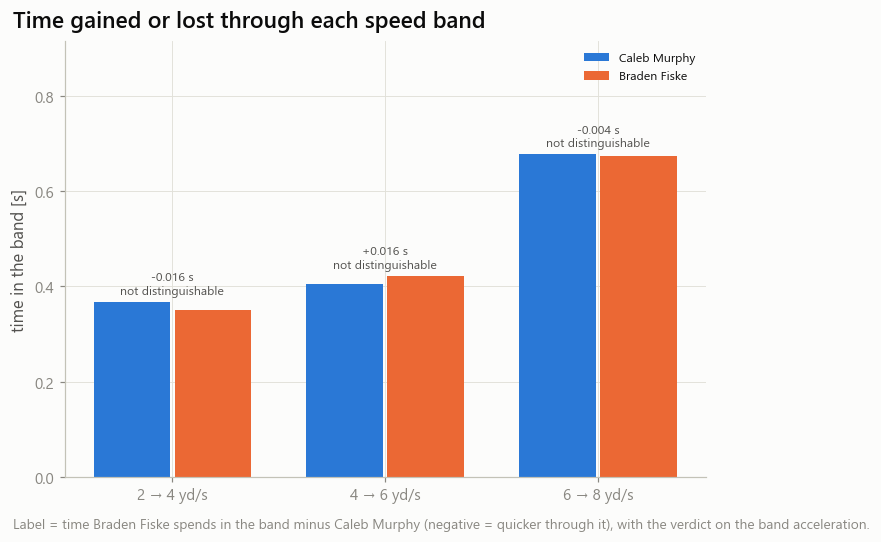

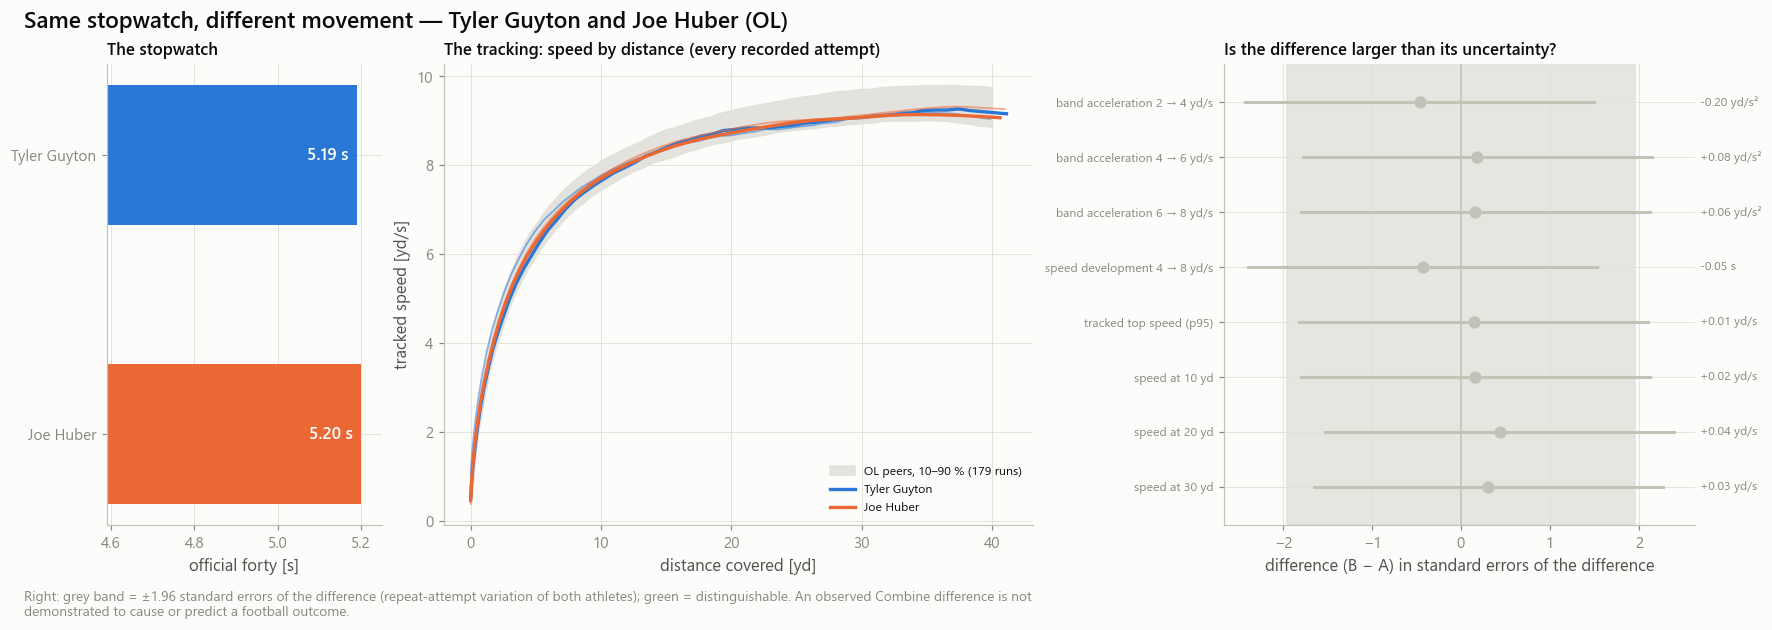

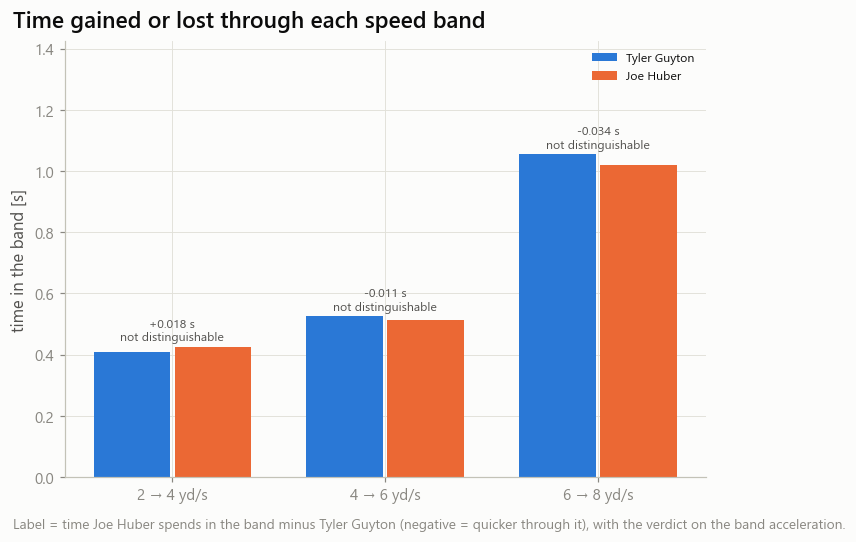

23 case report(s) written to reports/milestone09/cases


In [7]:
seqs = lambda i: windows.filter(pl.col('nfl_id') == i).sort('attempt_order')['seq_id'].to_list()[:2]
bands = {p: sfig.curve_band(frames, g['seq_id'].to_list()) for (p,), g in windows.partition_by(['position_group'], as_dict=True).items()}
CASE_DIR = store.reports_dir / 'cases'
written = []
TITLES = {'scout': 'Scout view', 'coach': 'Position-coach view', 'general_manager': 'General-manager view'}
COLS = ['label', 'unit', 'value_a', 'value_b', 'difference', 'ci_lower', 'ci_upper', 'verdict', 'evidence_status']
for c in cases.iter_rows(named=True):
    tw, d = TWIN[c['pair_id']], DIFF.get(c['pair_id'], [])
    names, ids = (c['name_a'], c['name_b']), (c['nfl_id_a'], c['nfl_id_b'])
    curves = {n: sfig.athlete_curves(frames, seqs(i)) for n, i in zip(names, ids)}
    fig_name = f'AM09D_01_case_{c["case_id"]}'
    store.show(ifg.fig_twin_story(tw, curves, bands.get(c['position_group']), d), fig_name, {'differences': diffs.filter(pl.col('pair_id') == c['pair_id'])},
               publication=True, source='scouting_cases + stopwatch_twin_differences + sequence_frames', n='two athletes, every recorded attempt', note=c['case_label'])
    store.show(ifg.fig_band_time(d, names), f'AM09D_02_band_time_{c["case_id"]}', {}, source='stopwatch_twin_differences', n='two athletes')
    if WRITE_CASE_REPORTS and controls.save_tables:
        svg = store.figures_dir / (fig_name + '.svg')
        frag = svg.read_text(encoding='utf-8') if svg.is_file() else ''
        figures = [('Stopwatch, tracked speed curves and the difference against its uncertainty.', frag[frag.find('<svg'):])] if '<svg' in frag else []
        page = sin.render_html(f'{c["name_a"]} and {c["name_b"]}', f'{c["case_label"]} · {c["position_group"]} · matched on: {c["matched_on"]}',
                               {TITLES[v]: secs for v, secs in VIEWS[c['case_id']].items()}, figures, [('Measured differences (B − A)', d, COLS)],
                               f'Case {c["case_id"]} · selected by a pre-draft rule · run mode {controls.run_mode} · generated {utc_now()}')
        CASE_DIR.mkdir(parents=True, exist_ok=True)
        (CASE_DIR / (c['case_id'] + '.html')).write_text(page, encoding='utf-8')
        written.append(c['case_id'])
print(f'{len(written)} case report(s) written to {cfg.paths.rel(CASE_DIR)}' if written else 'no case report written')

## 6 · Acceptance of the case studies

Informative criteria, read from the tables: at least eight grounded cases where supported · no case selected on an NFL outcome · three views per case · a practical scout follow-up in every case · generated wording passes the guard (it raised above otherwise).

In [8]:
follow = views.filter((pl.col('view') == 'scout') & (pl.col('section') == 'Film to examine')).group_by('case_id').len()
n_views = views.group_by('case_id').agg(pl.col('view').n_unique().alias('n'))
gate = pl.DataFrame([
    {'criterion': 'at_least_8_cases_where_supported', 'passed': cases.height >= 8, 'detail': f'{cases.height} case(s); absent types: {absent or "none"}'},
    {'criterion': 'no_case_selected_on_nfl_outcome', 'passed': not bool(cases['selected_using_nfl_outcome'].any()) if cases.height else True, 'detail': 'exposure count only, for one flagged type'},
    {'criterion': 'three_views_per_case', 'passed': n_views.height == cases.height and bool((n_views['n'] == 3).all()), 'detail': f'{n_views.height} case(s) with views'},
    {'criterion': 'scout_follow_up_in_every_case', 'passed': follow.height == cases.height, 'detail': f'{follow.height} case(s) with a film prompt or an explicit none'},
    {'criterion': 'every_displayed_metric_interpreted', 'passed': set(evidence['feature'].to_list()) <= set(interpretation['metric'].to_list()), 'detail': f'{interpretation.height} metrics'}])
with pl.Config(fmt_str_lengths=200, tbl_rows=-1):
    display(gate)
if controls.save_tables:
    store.write_json('scouting_cases_manifest', {'experiment_version': EXPERIMENT_VERSION, 'finished_at': utc_now(), 'n_cases': cases.height,
                                                 'case_types_found': sorted(cases['case_type'].unique().to_list()) if cases.height else [], 'case_types_absent': absent,
                                                 'reports_written': written, 'gate': gate.to_dicts(), 'provenance': PROV})
print('A case count below 8 is an honest state when the data do not support more: it is reported, not forced.')
print('Send back: the checks table, the case table, the absent types, the printed views of one case, the gate table, and one AM09D_01 figure.')
print('Next: 09e_application_data_mart.ipynb')

criterion,passed,detail
str,bool,str
"""at_least_8_cases_where_supported""",true,"""23 case(s); absent types: none"""
"""no_case_selected_on_nfl_outcome""",true,"""exposure count only, for one flagged type"""
"""three_views_per_case""",true,"""23 case(s) with views"""
"""scout_follow_up_in_every_case""",true,"""23 case(s) with a film prompt or an explicit none"""
"""every_displayed_metric_interpreted""",true,"""12 metrics"""


A case count below 8 is an honest state when the data do not support more: it is reported, not forced.
Send back: the checks table, the case table, the absent types, the printed views of one case, the gate table, and one AM09D_01 figure.
Next: 09e_application_data_mart.ipynb
